Task 01 - Data Preparation and Feature Engineering

In [ ]:
!pip install yfinance


In [ ]:
import pandas as pd
import numpy as np
import yfinance as yf
import datetime
import requests
import os
import zipfile

from google.colab import files

print("Libraries imported successfully!")

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("YFinance version:", yf.__version__)




Libraries imported successfully!
Pandas version: 2.2.3
NumPy version: 2.4.6
YFinance version: 0.2.66


Task 1.1 - Retrieve and save the S&P 500 ticker list

In [ ]:
import requests

# Read the S&P 500 company table
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

# Define a user-agent header to avoid HTTP 403 Forbidden error
headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36'}
response = requests.get(url, headers=headers)

tables = pd.read_html(response.text)

# Extract the company table
sp500 = tables[0]

# Select the ticker and company name
sp500 = sp500[["Symbol", "Security", "GICS Sector"]]

# Record retrieval date
retrieval_date = datetime.date.today()

# Save ticker list
sp500.to_csv("sp500_ticker_list.csv", index=False)

print("Retrieval date:", retrieval_date)
print("Number of companies:", len(sp500))

sp500.head(10)

Retrieval date: 2026-11-21
Number of companies: 503


/tmp/ipykernel_947/850718555.py:10: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  tables = pd.read_html(response.text)


,Symbol,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology
5,ADBE,Adobe Inc.,Information Technology
6,AMD,Advanced Micro Devices,Information Technology
7,AES,AES Corporation,Utilities
8,AFL,Aflac,Financials
9,A,Agilent Technologies,Health Care


In [ ]:
from google.colab import files

sp500.to_csv("01_sp500_ticker_list.csv", index=False)
files.download("01_sp500_ticker_list.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Convert ticker symbols into Yahoo Finance format
sp500["Yahoo_Ticker"] = sp500["Symbol"].str.replace(
    ".", "-", regex=False
)

sp500.head(10)

/tmp/ipykernel_947/2244555253.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sp500["Yahoo_Ticker"] = sp500["Symbol"].str.replace(


,Symbol,Security,GICS Sector,Yahoo_Ticker
0,MMM,3M,Industrials,MMM
1,AOS,A. O. Smith,Industrials,AOS
2,ABT,Abbott Laboratories,Health Care,ABT
3,ABBV,AbbVie,Health Care,ABBV
4,ACN,Accenture,Information Technology,ACN
5,ADBE,Adobe Inc.,Information Technology,ADBE
6,AMD,Advanced Micro Devices,Information Technology,AMD
7,AES,AES Corporation,Utilities,AES
8,AFL,Aflac,Financials,AFL
9,A,Agilent Technologies,Health Care,A


In [ ]:
#Testing the Yahoo Finance data retrieval
test_data = yf.download(
    "AAPL",
    start="2021-01-01",
    end="2025-01-01",
    auto_adjust=False,
    actions=True,
    progress=False
)

test_data.head()

Price,Adj Close,Close,Dividends,High,Low,Open,Stock Splits,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,,,,
2021-01-04,125.537102,129.410004,0.0,133.610001,126.760002,133.520004,0.0,143301900
2021-01-05,127.089241,131.009995,0.0,131.740005,128.429993,128.889999,0.0,97664900
2021-01-06,122.811188,126.599998,0.0,131.050003,126.379997,127.720001,0.0,155088000
2021-01-07,127.001923,130.919998,0.0,131.630005,127.860001,128.360001,0.0,109578200
2021-01-08,128.098129,132.050003,0.0,132.630005,130.229996,132.429993,0.0,105158200


In [ ]:
#Download S&P 500 benchmark data
benchmark = yf.download(
    "^GSPC",
    start="2021-01-01",
    end="2025-01-01",
    auto_adjust=False,
    actions=True,
    progress=False
)

benchmark.head()

Price,Adj Close,Close,Dividends,High,Low,Open,Stock Splits,Volume
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC
Date,,,,,,,,
2021-01-04,3700.649902,3700.649902,0.0,3769.989990,3662.709961,3764.610107,0.0,5015000000
2021-01-05,3726.860107,3726.860107,0.0,3737.830078,3695.070068,3698.020020,0.0,4591020000
2021-01-06,3748.139893,3748.139893,0.0,3783.040039,3705.340088,3712.199951,0.0,6064110000
2021-01-07,3803.790039,3803.790039,0.0,3811.550049,3764.709961,3764.709961,0.0,5099160000
2021-01-08,3824.679932,3824.679932,0.0,3826.689941,3783.600098,3815.050049,0.0,4773040000


In [ ]:
# Get Yahoo Finance ticker symbols
tickers = sp500["Yahoo_Ticker"].tolist()

# Add the S&P 500 benchmark
tickers.append("^GSPC")

# Download in batches of 50
all_data = []

for i in range(0, len(tickers), 50):

    batch_tickers = tickers[i:i+50]

    print("Downloading:", batch_tickers[0])

    batch_data = yf.download(
        batch_tickers,
        start="2021-01-01",
        end="2025-01-01",
        auto_adjust=False,
        actions=True,
        group_by="ticker",
        threads=False,
        progress=False
    )

    if not batch_data.empty:
        all_data.append(batch_data)

# Combine downloaded batches
raw_data = pd.concat(all_data, axis=1)

# Save original downloaded data
raw_data.to_csv("sp500_daily_raw.csv.gz", compression="gzip")

print("Download completed!")
print("Dataset shape:", raw_data.shape)

Downloading: MMM
Downloading: ADSK
Downloading: CMG
Downloading: D


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Downloading: F


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Downloading: PODD
Downloading: MRVL
Downloading: OKE


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Downloading: SPGI


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Downloading: TWLO


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Downloading: ZBRA
Download completed!
Dataset shape: (1005, 4022)


In [ ]:
benchmark = yf.download(
    "^GSPC",
    start="2021-01-01",
    end="2025-01-01",
    auto_adjust=False,
    actions=True,
    progress=False
)

display(benchmark.head())

Price,Adj Close,Close,Dividends,High,Low,Open,Stock Splits,Volume
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC
Date,,,,,,,,
2021-01-04,3700.649902,3700.649902,0.0,3769.989990,3662.709961,3764.610107,0.0,5015000000
2021-01-05,3726.860107,3726.860107,0.0,3737.830078,3695.070068,3698.020020,0.0,4591020000
2021-01-06,3748.139893,3748.139893,0.0,3783.040039,3705.340088,3712.199951,0.0,6064110000
2021-01-07,3803.790039,3803.790039,0.0,3811.550049,3764.709961,3764.709961,0.0,5099160000
2021-01-08,3824.679932,3824.679932,0.0,3826.689941,3783.600098,3815.050049,0.0,4773040000


In [ ]:
raw_data.to_csv("02_raw_stock_data.csv.gz", compression="gzip")
files.download("02_raw_stock_data.csv.gz")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
benchmark.to_csv("03_benchmark_data.csv")
files.download("03_benchmark_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Display the first 10 rows
display(raw_data.head(10))

Ticker             ADI                                                  \
Price             Open        High         Low       Close   Adj Close   
Date                                                                     
2021-01-04  148.449997  150.539993  144.619995  146.020004  132.622620   
2021-01-05  145.770004  148.669998  145.139999  148.630005  134.993179   
2021-01-06  147.729996  152.289993  147.110001  149.300003  135.601715   
2021-01-07  151.830002  156.210007  151.139999  155.610001  141.332703   
2021-01-08  156.020004  159.809998  155.820007  156.740005  142.359070   
2021-01-11  156.130005  159.199997  155.009995  158.300003  143.775955   
2021-01-12  157.009995  159.339996  156.520004  159.089996  144.493454   
2021-01-13  160.000000  161.779999  158.149994  158.479996  143.939407   
2021-01-14  159.179993  160.820007  159.179993  159.460007  144.829468   
2021-01-15  158.029999  159.059998  155.529999  157.750000  143.276367   

Ticker                                             ACN              ...  \
Price        Volume Dividends Stock Splits        Open        High  ...   
Date                                                                ...   
2021-01-04  2496600       0.0          0.0  261.000000  261.660004  ...   
2021-01-05  1513700       0.0          0.0  256.399994  258.640015  ...   
2021-01-06  2498200       0.0          0.0  259.200012  263.589996  ...   
2021-01-07  2661100       0.0          0.0  260.359985  264.920013  ...   
2021-01-08  4204900       0.0          0.0  263.809998  266.529999  ...   
2021-01-11  2609400       0.0          0.0  262.829987  264.709991  ...   
2021-01-12  2573800       0.0          0.0  260.119995  261.220001  ...   
2021-01-13  2622900       0.0          0.0  256.450012  259.089996  ...   
2021-01-14  2028100       0.0          0.0  257.250000  257.250000  ...   
2021-01-15  2338000       0.0          0.0  253.619995  255.970001  ...   

Ticker           ZBH                     ZBRA                          \
Price      Dividends Stock Splits        Open        High         Low   
Date                                                                    
2021-01-04       0.0          0.0  385.750000  387.000000  372.459991   
2021-01-05       0.0          0.0  376.510010  381.809998  374.970001   
2021-01-06       0.0          0.0  377.220001  397.119995  377.220001   
2021-01-07       0.0          0.0  395.899994  411.959991  395.149994   
2021-01-08       0.0          0.0  410.000000  415.450012  404.640015   
2021-01-11       0.0          0.0  402.119995  414.540009  400.190002   
2021-01-12       0.0          0.0  410.670013  419.209991  403.329987   
2021-01-13       0.0          0.0  409.200012  414.190002  406.820007   
2021-01-14       0.0          0.0  413.619995  418.750000  411.549988   
2021-01-15       0.0          0.0  410.739990  414.269989  406.630005   

Ticker                                                             
Price            Close   Adj Close  Volume Dividends Stock Splits  
Date                                                               
2021-01-04  378.130005  378.130005  432600       0.0          0.0  
2021-01-05  380.570007  380.570007  374700       0.0          0.0  
2021-01-06  394.820007  394.820007  419500       0.0          0.0  
2021-01-07  409.100006  409.100006  379900       0.0          0.0  
2021-01-08  405.470001  405.470001  348500       0.0          0.0  
2021-01-11  413.790009  413.790009  312600       0.0          0.0  
2021-01-12  407.950012  407.950012  313100       0.0          0.0  
2021-01-13  412.450012  412.450012  214700       0.0          0.0  
2021-01-14  411.980011  411.980011  247200       0.0          0.0  
2021-01-15  409.220001  409.220001  305800       0.0          0.0  

[10 rows x 4022 columns]

In [ ]:
print(raw_data.columns.names)
print(raw_data.columns.get_level_values(0).unique()[:10])

['Ticker', 'Price']
Index(['ADI', 'ACN', 'AFL', 'AEP', 'ATO', 'APTV', 'AON', 'ALGN', 'MO', 'AMP'], dtype='object', name='Ticker')


In [ ]:
#Prepare individual stock datasets
stock_data = {}

for ticker in sp500["Yahoo_Ticker"]:

    try:
        # Find the column level containing the ticker
        ticker_level = None

        for level in range(raw_data.columns.nlevels):
            if ticker in raw_data.columns.get_level_values(level):
                ticker_level = level
                break

        if ticker_level is None:
            continue

        share = raw_data.xs(
            ticker,
            axis=1,
            level=ticker_level
        )

        # Remove duplicate columns if present
        share = share.loc[:, ~share.columns.duplicated()]

        required = ["Close", "Adj Close", "Volume"]

#Retain required fields

        if all(col in share.columns for col in required):
            stock_data[ticker] = share[required].copy()

    except Exception as e:
        print("Could not prepare:", ticker, e)

print("Shares prepared:", len(stock_data))

Shares prepared: 503


Task 1.2 - Data Validation and alignment

In [ ]:
# Define the study period

study_start = pd.Timestamp("2021-01-01")
study_end = pd.Timestamp("2024-12-31")

# Extract benchmark adjusted closing prices

benchmark_adj = benchmark["Adj Close"]

# Handle the possibility of a single-column DataFrame
if isinstance(benchmark_adj, pd.DataFrame):
    benchmark_adj = benchmark_adj.iloc[:, 0]

# Remove missing benchmark observations
benchmark_adj = benchmark_adj.dropna()

# Convert benchmark index to datetime
benchmark_adj.index = pd.to_datetime(benchmark_adj.index)

# Remove timezone information if present
if benchmark_adj.index.tz is not None:
    benchmark_adj.index = benchmark_adj.index.tz_localize(None)

# Normalise dates
benchmark_adj.index = benchmark_adj.index.normalize()

# Restrict benchmark to the study period
benchmark_calendar = benchmark_adj.loc[
    study_start:study_end
].index

# Remove duplicate dates from the calendar
benchmark_calendar = benchmark_calendar[
    ~benchmark_calendar.duplicated()
].sort_values()

print("First benchmark trading date:", benchmark_calendar.min())
print("Last benchmark trading date:", benchmark_calendar.max())
print("Total benchmark trading dates:", len(benchmark_calendar))

First benchmark trading date: 2021-01-04 00:00:00
Last benchmark trading date: 2024-12-31 00:00:00
Total benchmark trading dates: 1005


In [ ]:
# Initialise validation results

validation_results = []

for ticker, original_df in stock_data.items():

    df = original_df.copy()

    # Standardise date index
    df.index = pd.to_datetime(df.index)

    if df.index.tz is not None:
        df.index = df.index.tz_localize(None)

    df.index = df.index.normalize()

    # Restrict data to the study period
    df = df.loc[study_start:study_end].sort_index()

    # Check duplicate dates
    duplicate_dates = int(df.index.duplicated().sum())

    # Remove duplicate dates temporarily for date alignment
    # Tickers with duplicates will be excluded later
    df_unique = df.loc[
        ~df.index.duplicated(keep="first")
    ]

    # Compare stock dates against benchmark trading dates
    missing_market_dates = benchmark_calendar.difference(
        df_unique.index
    )

    # Align the stock data with benchmark trading dates
    aligned_df = df_unique.reindex(benchmark_calendar)

    # Count missing values
    missing_close = int(aligned_df["Close"].isna().sum())
    missing_adj_close = int(aligned_df["Adj Close"].isna().sum())
    missing_volume = int(aligned_df["Volume"].isna().sum())

    # Check invalid prices
    nonpositive_close = int(
        (aligned_df["Close"].dropna() <= 0).sum()
    )

    nonpositive_adj_close = int(
        (aligned_df["Adj Close"].dropna() <= 0).sum()
    )

    # Check invalid volume
    negative_volume = int(
        (aligned_df["Volume"].dropna() < 0).sum()
    )

    zero_volume = int(
        (aligned_df["Volume"].dropna() == 0).sum()
    )

    # Identify dates with complete required data
    complete_rows = aligned_df[
        ["Close", "Adj Close", "Volume"]
    ].notna().all(axis=1)

    if complete_rows.any():

        first_valid_date = aligned_df.index[complete_rows].min()
        last_valid_date = aligned_df.index[complete_rows].max()

    else:

        first_valid_date = pd.NaT
        last_valid_date = pd.NaT

    # Store validation results
    validation_results.append({

        "Ticker": ticker,

        "Number_of_Rows": len(df),

        "Duplicate_Dates": duplicate_dates,

        "Missing_Close": missing_close,

        "Missing_Adj_Close": missing_adj_close,

        "Missing_Volume": missing_volume,

        "Missing_Market_Dates": len(missing_market_dates),

        "Nonpositive_Close": nonpositive_close,

        "Nonpositive_Adj_Close": nonpositive_adj_close,

        "Negative_Volume": negative_volume,

        "Zero_Volume": zero_volume,

        "First_Valid_Date": first_valid_date,

        "Last_Valid_Date": last_valid_date

    })

# Convert results into a DataFrame
validation_table = pd.DataFrame(validation_results)

# Display validation results
display(validation_table.head(20))

print("Total shares validated:", len(validation_table))

,Ticker,Number_of_Rows,Duplicate_Dates,Missing_Close,Missing_Adj_Close,Missing_Volume,Missing_Market_Dates,Nonpositive_Close,Nonpositive_Adj_Close,Negative_Volume,Zero_Volume,First_Valid_Date,Last_Valid_Date
0,MMM,1005,0,0,0,0,0,0,0,0,0,2021-01-04,2024-12-31
1,AOS,1005,0,0,0,0,0,0,0,0,0,2021-01-04,2024-12-31
2,ABT,1005,0,0,0,0,0,0,0,0,0,2021-01-04,2024-12-31
3,ABBV,1005,0,0,0,0,0,0,0,0,0,2021-01-04,2024-12-31
4,ACN,1005,0,0,0,0,0,0,0,0,0,2021-01-04,2024-12-31
5,ADBE,1005,0,0,0,0,0,0,0,0,0,2021-01-04,2024-12-31
6,AMD,1005,0,0,0,0,0,0,0,0,0,2021-01-04,2024-12-31
7,AES,1005,0,0,0,0,0,0,0,0,0,2021-01-04,2024-12-31
8,AFL,1005,0,0,0,0,0,0,0,0,0,2021-01-04,2024-12-31
9,A,1005,0,0,0,0,0,0,0,0,0,2021-01-04,2024-12-31


Total shares validated: 503


In [ ]:
# Create final exclusion log

exclusion_log = []

for _, row in validation_table.iterrows():

    reasons = []

    # Duplicate date check
    if row["Duplicate_Dates"] > 0:
        reasons.append("Duplicate trading dates")

    # Missing values
    if (
        row["Missing_Close"] > 0
        or row["Missing_Adj_Close"] > 0
        or row["Missing_Volume"] > 0
    ):
        reasons.append("Missing required values")

    # Missing expected trading dates
    if row["Missing_Market_Dates"] > 0:
        reasons.append("Incomplete trading-date history")

    # Non-positive prices
    if (
        row["Nonpositive_Close"] > 0
        or row["Nonpositive_Adj_Close"] > 0
    ):
        reasons.append("Non-positive prices")

    # Negative volume
    if row["Negative_Volume"] > 0:
        reasons.append("Negative volume")

    # Check historical coverage
    if pd.isna(row["First_Valid_Date"]):
        reasons.append("No valid historical data")

    else:

        if row["First_Valid_Date"] > benchmark_calendar.min():
            reasons.append("Incomplete starting-period history")

        if row["Last_Valid_Date"] < benchmark_calendar.max():
            reasons.append("Incomplete ending-period history")

    # Record excluded shares
    if reasons:

        exclusion_log.append({

            "Ticker": row["Ticker"],

            "Exclusion_Reason": "; ".join(reasons)

        })

# Create exclusion DataFrame
exclusion_table = pd.DataFrame(exclusion_log)

display(exclusion_table)

print("Total excluded shares:", len(exclusion_table))

,Ticker,Exclusion_Reason
0,APP,Missing required values; Incomplete starting-p...
1,COIN,Missing required values; Incomplete starting-p...
2,CEG,Missing required values; Incomplete starting-p...
3,EXE,Missing required values; Incomplete starting-p...
4,FDXF,Missing required values; No valid historical data
5,GEHC,Missing required values; Incomplete starting-p...
6,GEV,Missing required values; Incomplete starting-p...
7,HONA,Missing required values; No valid historical data
8,Q,Missing required values; No valid historical data
9,RDDT,Missing required values; Incomplete starting-p...


Total excluded shares: 15


In [ ]:
# Export validation results

validation_table.to_csv(
    "04_validation_results.csv",
    index=False
)

# Export final exclusion log

exclusion_table.to_csv(
    "05_exclusion_log.csv",
    index=False
)

files.download("04_validation_results.csv")
files.download("05_exclusion_log.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Identify excluded tickers
excluded_tickers = set(exclusion_table["Ticker"])

# Identify eligible tickers
valid_tickers = [
    ticker
    for ticker in stock_data.keys()
    if ticker not in excluded_tickers
]

# Create a separate dictionary containing only eligible shares
eligible_stock_data = {
    ticker: stock_data[ticker].copy()
    for ticker in valid_tickers
}

# Replace stock_data with eligible shares only
stock_data = eligible_stock_data

print("Total shares initially prepared:", len(validation_table))

print("Total excluded shares:", len(excluded_tickers))

print("Total eligible shares:", len(valid_tickers))

print("Eligible ticker examples:", valid_tickers[:10])

Total shares initially prepared: 503
Total excluded shares: 15
Total eligible shares: 488
Eligible ticker examples: ['MMM', 'AOS', 'ABT', 'ABBV', 'ACN', 'ADBE', 'AMD', 'AES', 'AFL', 'A']


In [ ]:
# Verify that all eligible shares have the same trading dates

eligible_date_counts = {
    ticker: len(stock_data[ticker])
    for ticker in valid_tickers
}

print("Eligible share trading-date counts:")

display(
    pd.Series(eligible_date_counts, name="Trading_Days")
    .value_counts()
    .rename_axis("Number_of_Trading_Days")
    .reset_index(name="Number_of_Shares")
)

# Check whether all eligible shares have identical date indexes

if valid_tickers:

    reference_dates = stock_data[valid_tickers[0]].index

    all_dates_match = all(
        stock_data[ticker].index.equals(reference_dates)
        for ticker in valid_tickers
    )

    print("Do all eligible shares have identical dates?", all_dates_match)

else:

    print("No eligible shares remain. Review the exclusion log.")

Eligible share trading-date counts:


,Number_of_Trading_Days,Number_of_Shares
0,1005,488


Do all eligible shares have identical dates? True


**1.3 Weekly return and weekly beta **

In [ ]:
# Extract benchmark adjusted closing prices

benchmark_adj = benchmark["Adj Close"].copy()

# Handle possible DataFrame output
if isinstance(benchmark_adj, pd.DataFrame):
    benchmark_adj = benchmark_adj.iloc[:, 0]

# Remove missing values
benchmark_adj = benchmark_adj.dropna()

# Convert index to datetime
benchmark_adj.index = pd.to_datetime(benchmark_adj.index)

# Remove timezone information if present
if benchmark_adj.index.tz is not None:
    benchmark_adj.index = benchmark_adj.index.tz_localize(None)

# Resample daily prices into Friday-ending weekly prices
benchmark_weekly_price = benchmark_adj.resample("W-FRI").last()

# Exclude incomplete first and final calendar weeks
benchmark_weekly_price = benchmark_weekly_price.loc[
    "2021-01-08":"2024-12-27"
]

print("Benchmark weekly prices:")
display(benchmark_weekly_price.head(10))

print("Number of weekly benchmark observations:",
      len(benchmark_weekly_price))

Benchmark weekly prices:


,^GSPC
Date,
2021-01-08,3824.679932
2021-01-15,3768.250000
2021-01-22,3841.469971
2021-01-29,3714.239990
2021-02-05,3886.830078
2021-02-12,3934.830078
2021-02-19,3906.709961
2021-02-26,3811.149902
2021-03-05,3841.939941


Number of weekly benchmark observations: 208


In [ ]:
# Create weekly adjusted price dataset

weekly_prices = pd.DataFrame(
    index=benchmark_weekly_price.index
)

for ticker in valid_tickers:

    # Extract daily adjusted closing prices
    daily_prices = stock_data[ticker]["Adj Close"].copy()

    # Convert index to datetime
    daily_prices.index = pd.to_datetime(daily_prices.index)

    # Remove timezone information if present
    if daily_prices.index.tz is not None:
        daily_prices.index = daily_prices.index.tz_localize(None)

    # Calculate Friday-ending weekly prices
    weekly = daily_prices.resample("W-FRI").last()

    # Align weekly prices to benchmark week labels
    weekly = weekly.reindex(weekly_prices.index)

    # Add company prices to the dataset
    weekly_prices[ticker] = weekly

# Add benchmark prices
weekly_prices["^GSPC"] = benchmark_weekly_price

# Display weekly prices
display(weekly_prices.head(10))

print("Weekly price dataset shape:", weekly_prices.shape)
print("Number of weekly periods:", len(weekly_prices))
print("Number of eligible shares:", len(valid_tickers))

/tmp/ipykernel_947/530914174.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  weekly_prices[ticker] = weekly
/tmp/ipykernel_947/530914174.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  weekly_prices[ticker] = weekly
/tmp/ipykernel_947/530914174.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.cop

,MMM,AOS,ABT,ABBV,ACN,ADBE,AMD,AES,AFL,A,...,WTW,WDAY,WYNN,XEL,XYL,YUM,ZBRA,ZBH,ZTS,^GSPC
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-08,113.781563,50.168697,99.498398,85.705215,238.995850,485.100006,94.580002,20.159027,38.810333,122.100464,...,188.708878,227.649994,104.901443,54.840771,100.191063,96.210411,405.470001,146.956512,157.178116,3824.679932
2021-01-15,113.050880,50.767223,99.621773,89.334633,230.271271,458.079987,88.209999,21.887852,40.546272,121.283646,...,191.498184,222.559998,102.207474,54.173618,96.570808,95.734512,409.220001,148.038208,151.054062,3768.250000
2021-01-22,115.434143,51.598026,101.000191,89.609467,231.287994,472.440002,92.790001,21.491331,40.502655,121.398979,...,191.359161,235.529999,103.381264,54.006832,95.731079,96.156532,408.839996,148.861053,152.945587,3841.469971
2021-01-29,119.954811,48.745399,110.622238,82.835815,219.622375,458.769989,85.639999,19.470243,39.412235,115.479401,...,188.060211,227.529999,95.761177,53.364681,90.123436,91.128273,387.829987,142.074860,144.442917,3714.239990
2021-02-05,122.242462,53.862331,111.016068,87.887749,230.171341,492.119995,87.900002,21.442017,39.647762,118.371918,...,207.492661,263.950012,112.560020,52.906010,91.616333,94.585190,407.109985,147.825546,149.153091,3886.830078
2021-02-12,123.036331,54.194473,114.775383,84.420105,233.739151,498.839996,93.769997,22.775160,40.930096,122.984550,...,210.745316,281.359985,113.387459,51.321499,92.484062,95.155823,477.739990,149.203110,156.110687,3934.830078
2021-02-19,121.549171,53.539158,110.129944,84.880829,230.852249,479.119995,89.580002,22.599533,42.239082,121.917870,...,208.484222,276.339996,118.977455,51.763489,93.326538,94.849075,490.940002,144.848511,149.827286,3906.709961
2021-02-26,120.530190,53.296780,107.212021,87.087524,227.774689,459.670013,84.510002,21.202530,42.072170,117.305229,...,204.462433,245.179993,126.741890,48.861328,93.158112,93.405563,499.429993,150.756363,145.369965,3811.149902
2021-03-05,124.482201,56.088642,104.947487,86.246872,226.512802,440.829987,78.519997,20.747507,43.881912,111.606712,...,211.301376,237.020004,128.271667,51.163036,93.794388,94.127312,478.149994,146.540421,136.417755,3841.939941


Weekly price dataset shape: (208, 489)
Number of weekly periods: 208
Number of eligible shares: 488


In [ ]:
# Check weekly date alignment

benchmark_week_labels = benchmark_weekly_price.index

all_week_labels_match = weekly_prices.index.equals(
    benchmark_week_labels
)

print("Do all shares and benchmark have identical weekly labels?",
      all_week_labels_match)

# Check missing weekly prices
missing_weekly_prices = weekly_prices.isna().sum()

missing_weekly_summary = (
    missing_weekly_prices[missing_weekly_prices > 0]
    .sort_values(ascending=False)
)

print("\nColumns containing missing weekly prices:")
display(missing_weekly_summary)

# Check total weekly periods
print("\nTotal weekly periods:", len(weekly_prices))

Do all shares and benchmark have identical weekly labels? True

Columns containing missing weekly prices:


,0



Total weekly periods: 208


In [ ]:
#weekly_prices.to_csv("06_weekly_adjusted_prices.csv")
#files.download("06_weekly_adjusted_prices.csv")

In [ ]:
# Calculate weekly returns

weekly_returns = weekly_prices.pct_change(
    fill_method=None
)

# Display weekly returns
display(weekly_returns.head(10))

print("Weekly returns dataset shape:", weekly_returns.shape)

,MMM,AOS,ABT,ABBV,ACN,ADBE,AMD,AES,AFL,A,...,WTW,WDAY,WYNN,XEL,XYL,YUM,ZBRA,ZBH,ZTS,^GSPC
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-15,-0.006422,0.011930,0.001240,0.042348,-0.036505,-0.055700,-0.067350,0.085759,0.044729,-0.006690,...,0.014781,-0.022359,-0.025681,-0.012165,-0.036134,-0.004946,0.009249,0.007361,-0.038963,-0.014754
2021-01-22,0.021081,0.016365,0.013837,0.003076,0.004415,0.031348,0.051922,-0.018116,-0.001076,0.000951,...,-0.000726,0.058276,0.011484,-0.003079,-0.008695,0.004408,-0.000929,0.005558,0.012522,0.019431
2021-01-29,0.039162,-0.055286,0.095268,-0.075591,-0.050438,-0.028935,-0.077056,-0.094042,-0.026922,-0.048761,...,-0.017240,-0.033966,-0.073709,-0.011890,-0.058577,-0.052292,-0.051389,-0.045587,-0.055593,-0.033120
2021-02-05,0.019071,0.104973,0.003560,0.060987,0.048032,0.072694,0.026390,0.101271,0.005976,0.025048,...,0.103331,0.160067,0.175424,-0.008595,0.016565,0.037935,0.049713,0.040476,0.032609,0.046467
2021-02-12,0.006494,0.006166,0.033863,-0.039455,0.015501,0.013655,0.066780,0.062174,0.032343,0.038967,...,0.015676,0.065959,0.007351,-0.029950,0.009471,0.006033,0.173491,0.009319,0.046647,0.012349
2021-02-19,-0.012087,-0.012092,-0.040474,0.005458,-0.012351,-0.039532,-0.044684,-0.007711,0.031981,-0.008673,...,-0.010729,-0.017842,0.049300,0.008612,0.009109,-0.003224,0.027630,-0.029186,-0.040250,-0.007146
2021-02-26,-0.008383,-0.004527,-0.026495,0.025998,-0.013331,-0.040595,-0.056597,-0.061816,-0.003952,-0.037834,...,-0.019291,-0.112760,0.065260,-0.056066,-0.001805,-0.015219,0.017293,0.040786,-0.029750,-0.024460
2021-03-05,0.032789,0.052383,-0.021122,-0.009653,-0.005540,-0.040986,-0.070879,-0.021461,0.043015,-0.048579,...,0.033448,-0.033282,0.012070,0.047107,0.006830,0.007727,-0.042609,-0.027965,-0.061582,0.008079


Weekly returns dataset shape: (208, 489)


In [ ]:
# Export weekly adjusted prices

weekly_prices.to_csv(
    "06_weekly_adjusted_prices.csv"
)

# Export weekly returns

weekly_returns.to_csv(
    "07_weekly_returns.csv"
)

print("Weekly prices and returns exported successfully.")

Weekly prices and returns exported successfully.


In [ ]:
files.download("06_weekly_adjusted_prices.csv")
files.download("07_weekly_returns.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Initialise results list

feature_results = []

# Extract benchmark weekly returns
benchmark_returns = weekly_returns["^GSPC"]

for ticker in valid_tickers:

    # Extract individual share weekly returns
    share_returns = weekly_returns[ticker]

    # Align share and benchmark returns using common week labels
    aligned = pd.concat(
        [share_returns, benchmark_returns],
        axis=1,
        join="inner"
    )

    # Remove weeks where either return is missing
    aligned = aligned.dropna()

    aligned.columns = [
        "Share_Return",
        "Benchmark_Return"
    ]

    # At least two observations are required
    if len(aligned) < 2:
        print("Insufficient aligned observations:", ticker)
        continue

    # Calculate arithmetic mean weekly return
    mean_return = aligned["Share_Return"].mean()

    # Calculate benchmark variance
    benchmark_variance = aligned["Benchmark_Return"].var()

    # Calculate beta
    if benchmark_variance > 0:

        beta = (
            aligned["Share_Return"].cov(
                aligned["Benchmark_Return"]
            ) / benchmark_variance
        )

    else:

        beta = np.nan

    # Store results
    feature_results.append({

        "Ticker": ticker,

        "Mean_Weekly_Return": mean_return,

        "Weekly_Beta": beta,

        "Weekly_Observations": len(aligned)

    })

# Create final risk and return table
risk_return_table = pd.DataFrame(feature_results)

display(risk_return_table.head(20))

print("Total companies with calculated results:",
      len(risk_return_table))

,Ticker,Mean_Weekly_Return,Weekly_Beta,Weekly_Observations
0,MMM,0.001142,0.869079,207
1,AOS,0.001991,1.042805,207
2,ABT,0.000971,0.583543,207
3,ABBV,0.003749,0.425365,207
4,ACN,0.002376,1.143300,207
5,ADBE,0.000990,1.553525,207
6,AMD,0.003624,1.877622,207
7,AES,-0.001420,1.143912,207
8,AFL,0.005004,0.707196,207
9,A,0.001121,1.074723,207


Total companies with calculated results: 488


In [ ]:
# Export weekly return and beta results

risk_return_table.to_csv(
    "08_weekly_return_beta.csv",
    index=False
)

files.download("08_weekly_return_beta.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Summary of weekly return and beta calculations

print("Total eligible shares:", len(valid_tickers))

print("Total companies with calculated results:",
      len(risk_return_table))

print("Weekly price periods:", len(weekly_prices))

print("Weekly return periods:", len(weekly_returns))

print("\nMissing values in final results:")

display(risk_return_table.isna().sum())

print("\nDescriptive statistics:")

display(
    risk_return_table[
        [
            "Mean_Weekly_Return",
            "Weekly_Beta",
            "Weekly_Observations"
        ]
    ].describe()
)

Total eligible shares: 488
Total companies with calculated results: 488
Weekly price periods: 208
Weekly return periods: 208

Missing values in final results:


,0
Ticker,0
Mean_Weekly_Return,0
Weekly_Beta,0
Weekly_Observations,0



Descriptive statistics:


,Mean_Weekly_Return,Weekly_Beta,Weekly_Observations
count,488.000000,488.000000,488.0
mean,0.002857,0.973868,207.0
std,0.002646,0.406550,0.0
min,-0.004468,0.055453,207.0
25%,0.001182,0.666634,207.0
50%,0.002629,0.950610,207.0
75%,0.004207,1.179289,207.0
max,0.017772,3.778560,207.0


In [ ]:
print("Weekly labels match:", all_week_labels_match)

print("First weekly date:", weekly_prices.index.min())

print("Last weekly date:", weekly_prices.index.max())

print("First 5 weekly prices:")
display(weekly_prices.head())

print("First 5 weekly returns:")
display(weekly_returns.head())

Weekly labels match: True
First weekly date: 2021-01-08 00:00:00
Last weekly date: 2024-12-27 00:00:00
First 5 weekly prices:


,MMM,AOS,ABT,ABBV,ACN,ADBE,AMD,AES,AFL,A,...,WTW,WDAY,WYNN,XEL,XYL,YUM,ZBRA,ZBH,ZTS,^GSPC
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-08,113.781563,50.168697,99.498398,85.705215,238.995850,485.100006,94.580002,20.159027,38.810333,122.100464,...,188.708878,227.649994,104.901443,54.840771,100.191063,96.210411,405.470001,146.956512,157.178116,3824.679932
2021-01-15,113.050880,50.767223,99.621773,89.334633,230.271271,458.079987,88.209999,21.887852,40.546272,121.283646,...,191.498184,222.559998,102.207474,54.173618,96.570808,95.734512,409.220001,148.038208,151.054062,3768.250000
2021-01-22,115.434143,51.598026,101.000191,89.609467,231.287994,472.440002,92.790001,21.491331,40.502655,121.398979,...,191.359161,235.529999,103.381264,54.006832,95.731079,96.156532,408.839996,148.861053,152.945587,3841.469971
2021-01-29,119.954811,48.745399,110.622238,82.835815,219.622375,458.769989,85.639999,19.470243,39.412235,115.479401,...,188.060211,227.529999,95.761177,53.364681,90.123436,91.128273,387.829987,142.074860,144.442917,3714.239990
2021-02-05,122.242462,53.862331,111.016068,87.887749,230.171341,492.119995,87.900002,21.442017,39.647762,118.371918,...,207.492661,263.950012,112.560020,52.906010,91.616333,94.585190,407.109985,147.825546,149.153091,3886.830078


First 5 weekly returns:


,MMM,AOS,ABT,ABBV,ACN,ADBE,AMD,AES,AFL,A,...,WTW,WDAY,WYNN,XEL,XYL,YUM,ZBRA,ZBH,ZTS,^GSPC
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-15,-0.006422,0.011930,0.001240,0.042348,-0.036505,-0.055700,-0.067350,0.085759,0.044729,-0.006690,...,0.014781,-0.022359,-0.025681,-0.012165,-0.036134,-0.004946,0.009249,0.007361,-0.038963,-0.014754
2021-01-22,0.021081,0.016365,0.013837,0.003076,0.004415,0.031348,0.051922,-0.018116,-0.001076,0.000951,...,-0.000726,0.058276,0.011484,-0.003079,-0.008695,0.004408,-0.000929,0.005558,0.012522,0.019431
2021-01-29,0.039162,-0.055286,0.095268,-0.075591,-0.050438,-0.028935,-0.077056,-0.094042,-0.026922,-0.048761,...,-0.017240,-0.033966,-0.073709,-0.011890,-0.058577,-0.052292,-0.051389,-0.045587,-0.055593,-0.033120
2021-02-05,0.019071,0.104973,0.003560,0.060987,0.048032,0.072694,0.026390,0.101271,0.005976,0.025048,...,0.103331,0.160067,0.175424,-0.008595,0.016565,0.037935,0.049713,0.040476,0.032609,0.046467


1.4 - RFM Analysis

In [ ]:
# Identify the common observation date

# Start with the benchmark trading calendar
common_dates = pd.DatetimeIndex(benchmark_calendar)

# Check date alignment for every eligible share
for ticker in valid_tickers:

    share_dates = pd.DatetimeIndex(
        stock_data[ticker].index
    )

    # Intersect with the available share dates
    common_dates = common_dates.intersection(
        share_dates
    )

# Restrict to the study period
common_dates = common_dates[
    (common_dates >= study_start) &
    (common_dates <= study_end)
]

# Check that common dates are available
if len(common_dates) == 0:
    raise ValueError("No common observation date found.")

# Latest common trading date
observation_date = common_dates.max()

print("Common observation date:", observation_date)
print("Number of common trading dates:", len(common_dates))
print("Number of eligible shares:", len(valid_tickers))

Common observation date: 2024-12-31 00:00:00
Number of common trading dates: 1005
Number of eligible shares: 488


In [ ]:
# Store high-volume event data for each eligible share

volume_event_data = {}

for ticker in valid_tickers:

    # Copy and sort the company's daily data
    df = stock_data[ticker].copy().sort_index()

    # Keep data within the study period and up to the observation date
    df = df.loc[
        study_start:observation_date
    ].copy()

    # Calculate average volume of the previous 20 trading sessions
    # shift(1) excludes the current day's volume
    df["Previous_20_Day_Average"] = (
        df["Volume"]
        .rolling(window=20, min_periods=20)
        .mean()
        .shift(1)
    )

    # Calculate twice the previous 20-session average
    df["Volume_Threshold"] = (
        2 * df["Previous_20_Day_Average"]
    )

    # Identify qualifying high-volume events
    df["High_Volume_Event"] = (
        df["Volume"] > df["Volume_Threshold"]
    ).fillna(False).astype(bool)

    # Store the results
    volume_event_data[ticker] = df

print("High-volume event calculations completed.")
print("Shares processed:", len(volume_event_data))

High-volume event calculations completed.
Shares processed: 488


In [ ]:
# Summarise high-volume events

event_summary = []

for ticker, df in volume_event_data.items():

    event_summary.append({

        "Ticker": ticker,

        "High_Volume_Days": int(
            df["High_Volume_Event"].sum()
        ),

        "First_Qualifiable_Date": (
            df["Previous_20_Day_Average"]
            .first_valid_index()
        ),

        "First_High_Volume_Event": (
            df.index[df["High_Volume_Event"]].min()
            if df["High_Volume_Event"].any()
            else pd.NaT
        ),

        "Latest_High_Volume_Event": (
            df.index[df["High_Volume_Event"]].max()
            if df["High_Volume_Event"].any()
            else pd.NaT
        )

    })

event_summary_table = pd.DataFrame(event_summary)

display(event_summary_table.head(20))

print("Companies analysed:", len(event_summary_table))

print(
    "Companies with at least one high-volume event:",
    (event_summary_table["High_Volume_Days"] > 0).sum()
)

print(
    "Companies without any high-volume events:",
    (event_summary_table["High_Volume_Days"] == 0).sum()
)

,Ticker,High_Volume_Days,First_Qualifiable_Date,First_High_Volume_Event,Latest_High_Volume_Event
0,MMM,57,2021-02-02,2021-03-19,2024-12-20
1,AOS,47,2021-02-02,2021-03-08,2024-12-20
2,ABT,28,2021-02-02,2021-03-19,2024-12-20
3,ABBV,33,2021-02-02,2021-03-17,2024-12-20
4,ACN,29,2021-02-02,2021-05-27,2024-12-20
5,ADBE,43,2021-02-02,2021-06-18,2024-12-13
6,AMD,28,2021-02-02,2021-04-28,2024-12-13
7,AES,37,2021-02-02,2021-03-04,2024-11-07
8,AFL,35,2021-02-02,2021-03-19,2024-12-20
9,A,29,2021-02-02,2021-02-17,2024-12-20


Companies analysed: 488
Companies with at least one high-volume event: 488
Companies without any high-volume events: 0


In [ ]:
event_summary_table.to_csv(
    "09_high_volume_event_summary.csv",
    index=False
)

files.download("09_high_volume_event_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Calculate RFM values for all eligible shares

rfm_results = []

for ticker in valid_tickers:

    # Retrieve the company's high-volume event data
    df = volume_event_data[ticker].copy()

    # Keep observations up to the common observation date
    df = df.loc[:observation_date].copy()

    # Select the latest 60 trading sessions
    last_60 = df.tail(60)

    # Check whether 60 sessions are available
    if len(last_60) != 60:

        raise ValueError(
            f"{ticker} has only {len(last_60)} sessions. "
            "Exactly 60 sessions are required."
        )

    # -------------------------
    # RECENCY
    # -------------------------

    # Identify all qualifying events in the study history
    all_events = df[
        df["High_Volume_Event"]
    ]

    if not all_events.empty:

        # Latest qualifying event date
        latest_event_date = all_events.index.max()

        # Calendar-day difference
        recency = (
            observation_date - latest_event_date
        ).days

    else:

        # No qualifying event
        latest_event_date = pd.NaT
        recency = np.nan

    # -------------------------
    # FREQUENCY
    # -------------------------

    # Count high-volume events in the latest 60 sessions
    frequency = int(
        last_60["High_Volume_Event"].sum()
    )

    # -------------------------
    # MONETARY
    # -------------------------

    # Calculate total Close × Volume over the latest 60 sessions
    monetary = (
        last_60["Close"] * last_60["Volume"]
    ).sum(min_count=60)

    # Store RFM results
    rfm_results.append({

        "Ticker": ticker,

        "Observation_Date": observation_date,

        "Latest_Event_Date": latest_event_date,

        "R_Recency": recency,

        "F_Frequency": frequency,

        "M_Monetary_USD": monetary,

        "Sessions_Used": len(last_60)

    })

# Create RFM DataFrame
rfm_table = pd.DataFrame(rfm_results)

# Display results
display(rfm_table.head(20))

print("Total RFM records:", len(rfm_table))

,Ticker,Observation_Date,Latest_Event_Date,R_Recency,F_Frequency,M_Monetary_USD,Sessions_Used
0,MMM,2024-12-31,2024-12-20,11,4,2.599146e+10,60
1,AOS,2024-12-31,2024-12-20,11,2,4.748980e+09,60
2,ABT,2024-12-31,2024-12-20,11,1,3.523027e+10,60
3,ABBV,2024-12-31,2024-12-20,11,3,6.837054e+10,60
4,ACN,2024-12-31,2024-12-20,11,2,5.199430e+10,60
5,ADBE,2024-12-31,2024-12-13,18,3,1.030403e+11,60
6,AMD,2024-12-31,2024-12-13,18,4,3.131659e+11,60
7,AES,2024-12-31,2024-11-07,54,3,1.119578e+10,60
8,AFL,2024-12-31,2024-12-20,11,2,1.328456e+10,60
9,A,2024-12-31,2024-12-20,11,2,1.400180e+10,60


Total RFM records: 488


1.4.1 - 1.4.3 - Recency, Frequency and Monetary

In [ ]:
# Export RFM results

rfm_table.to_csv(
    "10_rfm_results.csv",
    index=False
)

files.download("10_rfm_results.csv")

print("RFM results exported successfully.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

RFM results exported successfully.


In [ ]:
# RFM validation checks

print("Total eligible shares:", len(valid_tickers))

print("Total RFM records:", len(rfm_table))

print(
    "All records use the same observation date:",
    rfm_table["Observation_Date"].nunique() == 1
)

print(
    "All records use exactly 60 sessions:",
    (rfm_table["Sessions_Used"] == 60).all()
)

print(
    "Minimum Frequency:",
    rfm_table["F_Frequency"].min()
)

print(
    "Maximum Frequency:",
    rfm_table["F_Frequency"].max()
)

print(
    "Companies with no high-volume event:",
    rfm_table["R_Recency"].isna().sum()
)

print(
    "Companies with a high-volume event:",
    rfm_table["R_Recency"].notna().sum()
)

print(
    "Missing Frequency values:",
    rfm_table["F_Frequency"].isna().sum()
)

print(
    "Missing Monetary values:",
    rfm_table["M_Monetary_USD"].isna().sum()
)

print("\nRFM descriptive statistics:")

display(
    rfm_table[
        [
            "R_Recency",
            "F_Frequency",
            "M_Monetary_USD",
            "Sessions_Used"
        ]
    ].describe()
)

Total eligible shares: 488
Total RFM records: 488
All records use the same observation date: True
All records use exactly 60 sessions: True
Minimum Frequency: 0
Maximum Frequency: 8
Companies with no high-volume event: 0
Companies with a high-volume event: 488
Missing Frequency values: 0
Missing Monetary values: 0

RFM descriptive statistics:


,R_Recency,F_Frequency,M_Monetary_USD,Sessions_Used
count,488.000000,488.000000,4.880000e+02,488.0
mean,20.389344,2.987705,3.930290e+10,60.0
std,21.302843,1.328820,1.288833e+11,0.0
min,4.000000,0.000000,1.297483e+09,60.0
25%,11.000000,2.000000,1.023194e+10,60.0
50%,11.000000,3.000000,1.668382e+10,60.0
75%,15.000000,4.000000,3.210048e+10,60.0
max,222.000000,8.000000,1.847697e+12,60.0


Task 1.5 – RFM and risk-return analysis, validation and interpretation

In [ ]:
# Task 1.5 – Step 1.1: Create the combined feature dataset

# Make sure Ticker is a column in each dataset
for df_name, df in [
    ("risk_return_table", risk_return_table),
    ("rfm_table", rfm_table),
    ("company_details", company_details)
]:
    if "Ticker" not in df.columns:
        df.reset_index(inplace=True)
        df.rename(columns={df.columns[0]: "Ticker"}, inplace=True)

# Combine risk-return measures and RFM measures
feature_table = risk_return_table.merge(
    rfm_table,
    on="Ticker",
    how="inner"
)

# Add company information
feature_table = feature_table.merge(
    company_details,
    on="Ticker",
    how="left"
)

print("Final number of companies:", len(feature_table))
display(feature_table.head())

Final number of companies: 488


,Ticker,Mean_Weekly_Return,Weekly_Beta,Weekly_Observations,Observation_Date,Latest_Event_Date,R_Recency,F_Frequency,M_Monetary_USD,Sessions_Used,Company,Sector
0,MMM,0.001142,0.869079,207,2024-12-31,2024-12-20,11,4,2.599146e+10,60,3M,Industrials
1,AOS,0.001991,1.042805,207,2024-12-31,2024-12-20,11,2,4.748980e+09,60,A. O. Smith,Industrials
2,ABT,0.000971,0.583543,207,2024-12-31,2024-12-20,11,1,3.523027e+10,60,Abbott Laboratories,Health Care
3,ABBV,0.003749,0.425365,207,2024-12-31,2024-12-20,11,3,6.837054e+10,60,AbbVie,Health Care
4,ACN,0.002376,1.143300,207,2024-12-31,2024-12-20,11,2,5.199430e+10,60,Accenture,Information Technology


In [ ]:
# Task 1.5 – Step 1.2: Validate the final feature dataset

print("Number of companies:", len(feature_table))
print("Duplicate tickers:", feature_table["Ticker"].duplicated().sum())

print("\nMissing values:")
display(feature_table.isnull().sum())

print("\nNumerical feature summary:")
display(feature_table.select_dtypes(include="number").describe())

Number of companies: 488
Duplicate tickers: 0

Missing values:


,0
Ticker,0
Mean_Weekly_Return,0
Weekly_Beta,0
Weekly_Observations,0
Observation_Date,0
Latest_Event_Date,0
R_Recency,0
F_Frequency,0
M_Monetary_USD,0
Sessions_Used,0



Numerical feature summary:


,Mean_Weekly_Return,Weekly_Beta,Weekly_Observations,R_Recency,F_Frequency,M_Monetary_USD,Sessions_Used
count,488.000000,488.000000,488.0,488.000000,488.000000,4.880000e+02,488.0
mean,0.002857,0.973868,207.0,20.389344,2.987705,3.930290e+10,60.0
std,0.002646,0.406550,0.0,21.302843,1.328820,1.288833e+11,0.0
min,-0.004468,0.055453,207.0,4.000000,0.000000,1.297483e+09,60.0
25%,0.001182,0.666634,207.0,11.000000,2.000000,1.023194e+10,60.0
50%,0.002629,0.950610,207.0,11.000000,3.000000,1.668382e+10,60.0
75%,0.004207,1.179289,207.0,15.000000,4.000000,3.210048e+10,60.0
max,0.017772,3.778560,207.0,222.000000,8.000000,1.847697e+12,60.0


In [ ]:
# Check that all companies have the required measurements

required_columns = [
    "Mean_Weekly_Return",
    "Weekly_Beta",
    "R_Recency",
    "F_Frequency",
    "M_Monetary_USD"
]

print("Required columns available:")
print([col for col in required_columns if col in feature_table.columns])

print("\nMissing values in required features:")
display(feature_table[required_columns].isnull().sum())

Required columns available:
['Mean_Weekly_Return', 'Weekly_Beta', 'R_Recency', 'F_Frequency', 'M_Monetary_USD']

Missing values in required features:


,0
Mean_Weekly_Return,0
Weekly_Beta,0
R_Recency,0
F_Frequency,0
M_Monetary_USD,0


In [ ]:
# Task 1.5 – Step 1.3: Descriptive analysis

analysis_columns = [
    "Mean_Weekly_Return",
    "Weekly_Beta",
    "R_Recency",
    "F_Frequency",
    "M_Monetary_USD"
]

feature_summary = feature_table[analysis_columns].describe().T

display(feature_summary)

,count,mean,std,min,25%,50%,75%,max
Mean_Weekly_Return,488.0,2.857285e-03,2.646164e-03,-4.468094e-03,1.182416e-03,2.629158e-03,4.206779e-03,1.777248e-02
Weekly_Beta,488.0,9.738679e-01,4.065500e-01,5.545261e-02,6.666344e-01,9.506099e-01,1.179289e+00,3.778560e+00
R_Recency,488.0,2.038934e+01,2.130284e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.500000e+01,2.220000e+02
F_Frequency,488.0,2.987705e+00,1.328820e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00
M_Monetary_USD,488.0,3.930290e+10,1.288833e+11,1.297483e+09,1.023194e+10,1.668382e+10,3.210048e+10,1.847697e+12


In [ ]:
# Companies with the highest weekly returns
display(
    feature_table.nlargest(5, "Mean_Weekly_Return")[
        ["Ticker", "Mean_Weekly_Return", "Weekly_Beta"]
    ]
)

# Companies with the highest beta values
display(
    feature_table.nlargest(5, "Weekly_Beta")[
        ["Ticker", "Mean_Weekly_Return", "Weekly_Beta"]
    ]
)

# Companies with the highest trading frequency
display(
    feature_table.nlargest(5, "F_Frequency")[
        ["Ticker", "F_Frequency", "M_Monetary_USD"]
    ]
)

,Ticker,Mean_Weekly_Return,Weekly_Beta
411,SMCI,0.017772,1.783662
333,NVDA,0.013624,2.125953
457,VRT,0.012583,2.001479
461,VST,0.011395,1.018537
117,FIX,0.011297,1.336791


,Ticker,Mean_Weekly_Return,Weekly_Beta
85,CVNA,0.010964,3.778560
65,XYZ,-0.001554,2.504520
114,COHR,0.003887,2.139305
333,NVDA,0.013624,2.125953
437,TWLO,-0.002161,2.073379


,Ticker,F_Frequency,M_Monetary_USD
103,CI,8,3.789504e+10
222,HSY,8,2.273531e+10
198,FOXA,7,9.388144e+09
448,UNH,7,1.513083e+11
482,XEL,7,1.504183e+10


In [ ]:
# Task 1.5 – Step 1.4: Worked example for Apple (AAPL)

ticker = "AAPL"

print("Company:", ticker)

# Display the final calculated features
display(
    feature_table.loc[
        feature_table["Ticker"] == ticker,
        ["Ticker"] + analysis_columns
    ]
)

# Show the latest 60 trading sessions used for Monetary and Frequency
aapl_last_60 = volume_event_data[ticker].tail(60)

print("Number of trading sessions:", len(aapl_last_60))
print("High-volume events:", int(aapl_last_60["High_Volume_Event"].sum()))

aapl_monetary = (
    aapl_last_60["Close"] * aapl_last_60["Volume"]
).sum()

print("Monetary value (USD):", aapl_monetary)

# Show the latest qualifying high-volume event
aapl_events = volume_event_data[ticker].loc[
    volume_event_data[ticker]["High_Volume_Event"]
]

if not aapl_events.empty:
    latest_event = aapl_events.index.max()
    recency = (observation_date - latest_event).days
    print("Latest high-volume event:", latest_event)
    print("Recency in calendar days:", recency)
else:
    print("No qualifying high-volume event found.")

Company: AAPL


,Ticker,Mean_Weekly_Return,Weekly_Beta,R_Recency,F_Frequency,M_Monetary_USD
38,AAPL,0.00393,1.174834,11,2,6.233034e+11


Number of trading sessions: 60
High-volume events: 2
Monetary value (USD): 623303377706.5842
Latest high-volume event: 2024-12-20 00:00:00
Recency in calendar days: 11


In [ ]:
# Task 1.5 – Step 1.5: Validate high-volume event calculations

event_validation = []

for ticker, df in volume_event_data.items():

    event_validation.append({
        "Ticker": ticker,
        "Total_Trading_Days": len(df),
        "Qualifiable_Days": int(df["Previous_20_Day_Average"].notna().sum()),
        "High_Volume_Events": int(df["High_Volume_Event"].sum()),
        "No_Event": not df["High_Volume_Event"].any(),
        "Missing_Threshold": int(df["Volume_Threshold"].isna().sum())
    })

event_validation_table = pd.DataFrame(event_validation)

display(event_validation_table.head())

print("Total companies checked:", len(event_validation_table))
print("Companies with no high-volume events:",
      event_validation_table["No_Event"].sum())
print("Companies with missing thresholds:",
      event_validation_table["Missing_Threshold"].sum())

,Ticker,Total_Trading_Days,Qualifiable_Days,High_Volume_Events,No_Event,Missing_Threshold
0,MMM,1005,985,57,False,20
1,AOS,1005,985,47,False,20
2,ABT,1005,985,28,False,20
3,ABBV,1005,985,33,False,20
4,ACN,1005,985,29,False,20


Total companies checked: 488
Companies with no high-volume events: 0
Companies with missing thresholds: 9760


In [ ]:
# Task 1.5 – Step 1.6: Prepare the common dataset for clustering

clustering_features = [
    "Mean_Weekly_Return",
    "Weekly_Beta",
    "R_Recency",
    "F_Frequency",
    "M_Monetary_USD"
]

clustering_data = feature_table[
    ["Ticker"] + clustering_features
].copy()

# Identify companies with missing feature values
missing_feature_companies = clustering_data[
    clustering_data[clustering_features].isnull().any(axis=1)
]

print("Companies with missing feature values:",
      len(missing_feature_companies))

# Retain companies with complete feature values
clustering_data = clustering_data.dropna(
    subset=clustering_features
)

print("Companies available for clustering:",
      len(clustering_data))

display(clustering_data.head())

Companies with missing feature values: 0
Companies available for clustering: 488


,Ticker,Mean_Weekly_Return,Weekly_Beta,R_Recency,F_Frequency,M_Monetary_USD
0,MMM,0.001142,0.869079,11,4,2.599146e+10
1,AOS,0.001991,1.042805,11,2,4.748980e+09
2,ABT,0.000971,0.583543,11,1,3.523027e+10
3,ABBV,0.003749,0.425365,11,3,6.837054e+10
4,ACN,0.002376,1.143300,11,2,5.199430e+10


In [ ]:
# Create a ZIP file containing all generated output files

import os
import zipfile
from google.colab import files

folder_path = "/content"
zip_filename = "/content/Task_1_Stock_Analysis_Files.zip"

files_added = []

with zipfile.ZipFile(zip_filename, "w", zipfile.ZIP_DEFLATED) as zipf:

    for root, dirs, filenames in os.walk(folder_path):

        for filename in filenames:

            file_path = os.path.join(root, filename)

            # Avoid adding the ZIP file itself
            if file_path == zip_filename:
                continue

            # Add files to ZIP
            zipf.write(
                file_path,
                os.path.relpath(file_path, folder_path)
            )

            files_added.append(filename)

print("Files included in ZIP:", len(files_added))

for filename in files_added:
    print("-", filename)

# Download ZIP file
files.download(zip_filename)

Files included in ZIP: 40
- Task1_All_Tables.zip
- 09_high_volume_event_summary.csv
- 15_missing_data_diagnostic.csv
- 08_weekly_return_beta.csv
- 01_sp500_ticker_list.csv
- 13_AAPL_worked_example.csv
- 10_rfm_results.csv
- 16_final_exclusion_log.csv
- sp500_ticker_list.csv
- 11_final_feature_table.csv
- 14_corporate_actions_summary.csv
- 12_feature_summary_statistics.csv
- 04_validation_results.csv
- 02_raw_stock_data.csv.gz
- sp500_daily_raw.csv.gz
- 03_benchmark_data.csv
- 06_weekly_adjusted_prices.csv
- 07_weekly_returns.csv
- 05_exclusion_log.csv
- default_configs.db
- gce
- .last_update_check.json
- hidden_gcloud_config_universe_descriptor_data_cache_configs.db
- config_sentinel
- active_config
- .last_survey_prompt.yaml
- .last_opt_in_prompt.yaml
- 22.18.15.518759.log
- 22.18.38.571729.log
- 22.18.53.588181.log
- 22.18.45.880512.log
- 22.18.52.867204.log
- 22.18.44.768076.log
- config_default
- anscombe.json
- README.md
- california_housing_train.csv
- mnist_test.csv
- mnist_tra

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Task 2 Stock Segmentation and Sensitivity Analysis

2.1 Feature preparation

In [ ]:
# Task 2.1 – Step 1: Prepare the two feature matrices

import pandas as pd
import numpy as np

# Check available columns
print("Available columns:")
print(feature_table.columns.tolist())

# Risk and return features
risk_return_features = [
    "Mean_Weekly_Return",
    "Weekly_Beta"
]

# Trading activity features
trading_activity_features = [
    "R_Recency",
    "F_Frequency",
    "M_Monetary_USD"
]

# Create separate feature matrices
risk_return_matrix = feature_table[
    ["Ticker"] + risk_return_features
].copy()

trading_activity_matrix = feature_table[
    ["Ticker"] + trading_activity_features
].copy()

# Remove rows with missing or infinite values separately
risk_return_matrix.replace([np.inf, -np.inf], np.nan, inplace=True)
trading_activity_matrix.replace([np.inf, -np.inf], np.nan, inplace=True)

risk_return_matrix.dropna(
    subset=risk_return_features,
    inplace=True
)

trading_activity_matrix.dropna(
    subset=trading_activity_features,
    inplace=True
)

# Reset indexes
risk_return_matrix.reset_index(drop=True, inplace=True)
trading_activity_matrix.reset_index(drop=True, inplace=True)

# Display results
print("\nRisk and Return Matrix")
print("Number of companies:", len(risk_return_matrix))
display(risk_return_matrix.head())

print("\nTrading Activity Matrix")
print("Number of companies:", len(trading_activity_matrix))
display(trading_activity_matrix.head())

print("\nMissing values in Risk and Return:")
display(risk_return_matrix.isnull().sum())

print("\nMissing values in Trading Activity:")
display(trading_activity_matrix.isnull().sum())

Available columns:
['Ticker', 'Mean_Weekly_Return', 'Weekly_Beta', 'Weekly_Observations', 'Observation_Date', 'Latest_Event_Date', 'R_Recency', 'F_Frequency', 'M_Monetary_USD', 'Sessions_Used', 'Company', 'Sector']

Risk and Return Matrix
Number of companies: 488


,Ticker,Mean_Weekly_Return,Weekly_Beta
0,MMM,0.001142,0.869079
1,AOS,0.001991,1.042805
2,ABT,0.000971,0.583543
3,ABBV,0.003749,0.425365
4,ACN,0.002376,1.143300



Trading Activity Matrix
Number of companies: 488


,Ticker,R_Recency,F_Frequency,M_Monetary_USD
0,MMM,11,4,2.599146e+10
1,AOS,11,2,4.748980e+09
2,ABT,11,1,3.523027e+10
3,ABBV,11,3,6.837054e+10
4,ACN,11,2,5.199430e+10



Missing values in Risk and Return:


,0
Ticker,0
Mean_Weekly_Return,0
Weekly_Beta,0



Missing values in Trading Activity:


,0
Ticker,0
R_Recency,0
F_Frequency,0
M_Monetary_USD,0


In [ ]:
# Task 2.1 – Step 2: Inspect skewness and outliers

import matplotlib.pyplot as plt

# Define the numerical features in each matrix
all_feature_matrices = {
    "Risk and Return": (
        risk_return_matrix,
        ["Mean_Weekly_Return", "Weekly_Beta"]
    ),
    "Trading Activity": (
        trading_activity_matrix,
        ["R_Recency", "F_Frequency", "M_Monetary_USD"]
    )
}

# Store the analysis results
distribution_results = []

for matrix_name, (matrix, columns) in all_feature_matrices.items():

    for column in columns:

        values = matrix[column]

        # Calculate quartiles and IQR
        Q1 = values.quantile(0.25)
        Q3 = values.quantile(0.75)
        IQR = Q3 - Q1

        # Calculate lower and upper outlier boundaries
        lower_bound = Q1 - (1.5 * IQR)
        upper_bound = Q3 + (1.5 * IQR)

        # Count potential outliers
        outliers = values[
            (values < lower_bound) | (values > upper_bound)
        ]

        distribution_results.append({
            "Matrix": matrix_name,
            "Feature": column,
            "Skewness": values.skew(),
            "Minimum": values.min(),
            "Maximum": values.max(),
            "Q1": Q1,
            "Median": values.median(),
            "Q3": Q3,
            "IQR": IQR,
            "Lower_Bound": lower_bound,
            "Upper_Bound": upper_bound,
            "Outlier_Count": len(outliers),
            "Outlier_Percentage": (len(outliers) / len(values)) * 100
        })

# Display results
distribution_summary = pd.DataFrame(distribution_results)

display(distribution_summary.round(4))

,Matrix,Feature,Skewness,Minimum,Maximum,Q1,Median,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,Risk and Return,Mean_Weekly_Return,0.8692,-4.500000e-03,1.780000e-02,1.200000e-03,2.600000e-03,4.200000e-03,3.000000e-03,-3.400000e-03,8.700000e-03,15,3.0738
1,Risk and Return,Weekly_Beta,1.1043,5.550000e-02,3.778600e+00,6.666000e-01,9.506000e-01,1.179300e+00,5.127000e-01,-1.023000e-01,1.948300e+00,10,2.0492
2,Trading Activity,R_Recency,3.6534,4.000000e+00,2.220000e+02,1.100000e+01,1.100000e+01,1.500000e+01,4.000000e+00,5.000000e+00,2.100000e+01,113,23.1557
3,Trading Activity,F_Frequency,0.4286,0.000000e+00,8.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,2.000000e+00,-1.000000e+00,7.000000e+00,2,0.4098
4,Trading Activity,M_Monetary_USD,11.7073,1.297483e+09,1.847697e+12,1.023194e+10,1.668382e+10,3.210048e+10,2.186854e+10,-2.257086e+10,6.490329e+10,45,9.2213


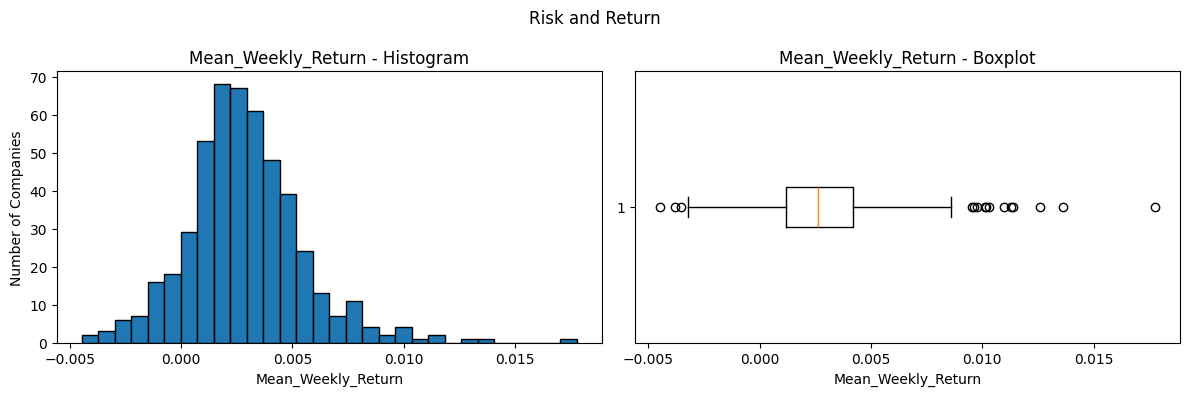

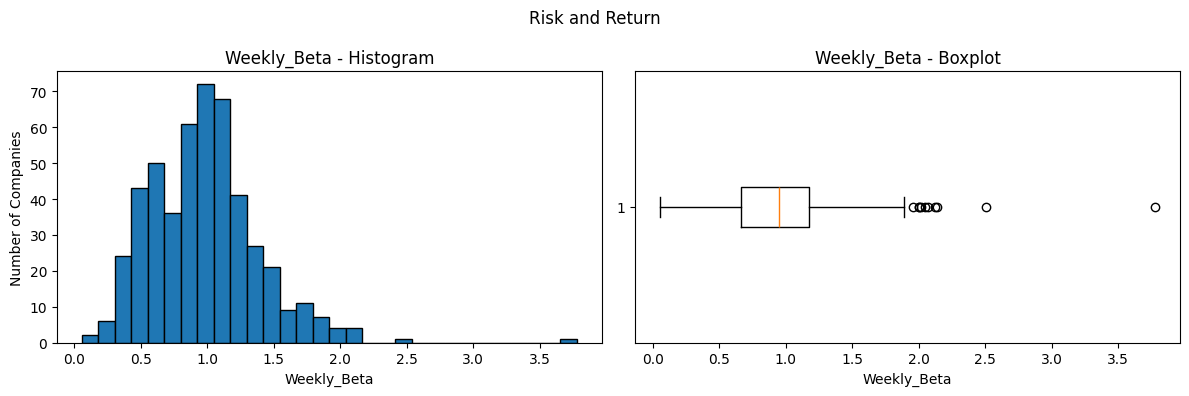

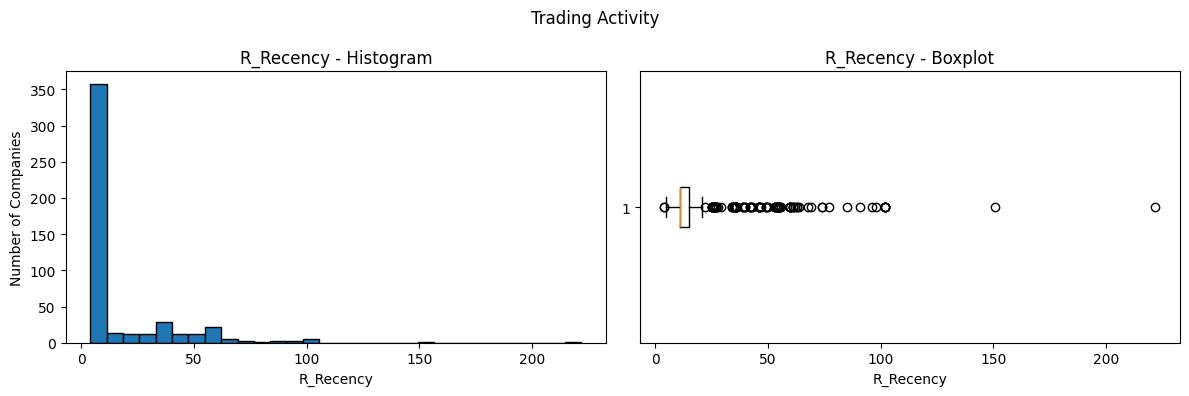

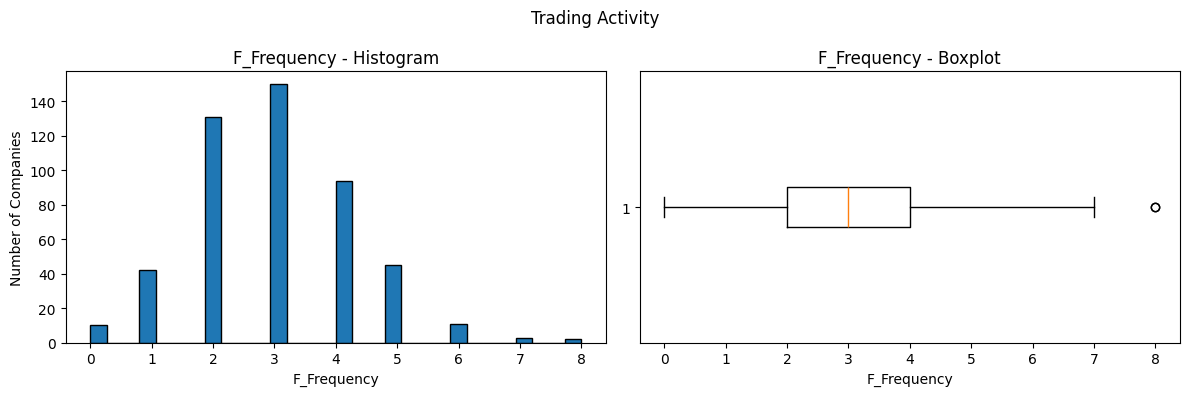

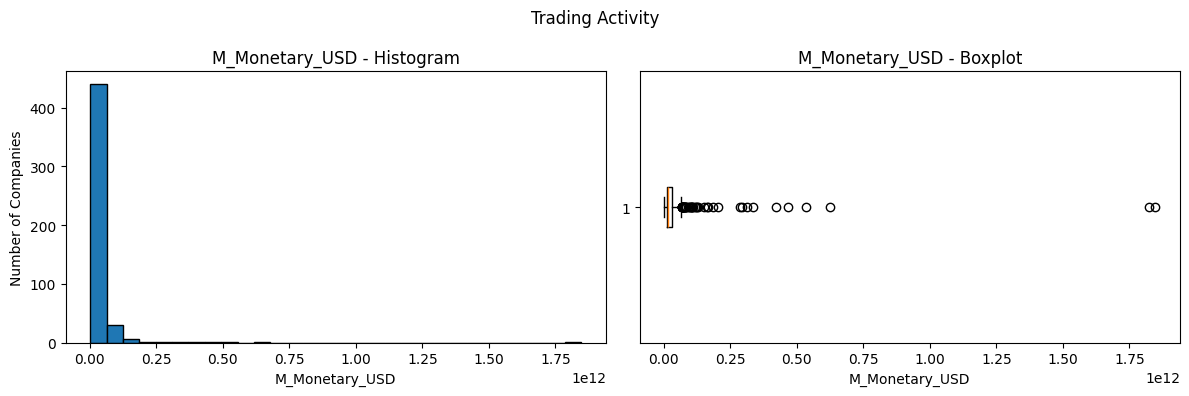

In [ ]:
# Task 2.1 – Step 2.2: Visual inspection of distributions

for matrix_name, (matrix, columns) in all_feature_matrices.items():

    for column in columns:

        fig, axes = plt.subplots(1, 2, figsize=(12, 4))

        # Histogram
        axes[0].hist(matrix[column], bins=30, edgecolor="black")
        axes[0].set_title(f"{column} - Histogram")
        axes[0].set_xlabel(column)
        axes[0].set_ylabel("Number of Companies")

        # Boxplot
        axes[1].boxplot(matrix[column], vert=False)
        axes[1].set_title(f"{column} - Boxplot")
        axes[1].set_xlabel(column)

        fig.suptitle(matrix_name)
        plt.tight_layout()
        plt.show()

In [ ]:
# Task 2.1 – Step 3: Apply log1p transformation to Monetary

# Create a copy of the trading activity matrix
trading_activity_transformed = trading_activity_matrix.copy()

# Check that Monetary values are non-negative
print("Minimum Monetary value:",
      trading_activity_transformed["M_Monetary_USD"].min())

if (trading_activity_transformed["M_Monetary_USD"] < 0).any():
    raise ValueError("Monetary contains negative values. Check the data.")

# Apply log1p transformation
trading_activity_transformed["M_Monetary_Log"] = np.log1p(
    trading_activity_transformed["M_Monetary_USD"]
)

# Display original and transformed values
display(
    trading_activity_transformed[
        ["Ticker", "M_Monetary_USD", "M_Monetary_Log"]
    ].head()
)

Minimum Monetary value: 1297482617.047882


,Ticker,M_Monetary_USD,M_Monetary_Log
0,MMM,2.599146e+10,23.981034
1,AOS,4.748980e+09,22.281196
2,ABT,3.523027e+10,24.285172
3,ABBV,6.837054e+10,24.948208
4,ACN,5.199430e+10,24.674400


In [ ]:
# Task 2.1 – Step 4: Compare Monetary skewness

monetary_skewness = pd.DataFrame({
    "Version": ["Original Monetary", "Log-transformed Monetary"],
    "Skewness": [
        trading_activity_transformed["M_Monetary_USD"].skew(),
        trading_activity_transformed["M_Monetary_Log"].skew()
    ]
})

display(monetary_skewness.round(4))

,Version,Skewness
0,Original Monetary,11.7073
1,Log-transformed Monetary,1.0837


In [ ]:
# Task 2.1 – Step 5: Create final feature matrices

# Risk and return feature matrix
risk_return_final = risk_return_matrix[
    ["Ticker", "Mean_Weekly_Return", "Weekly_Beta"]
].copy()

# Trading activity feature matrix
trading_activity_final = trading_activity_transformed[
    ["Ticker", "R_Recency", "F_Frequency", "M_Monetary_Log"]
].copy()

print("Risk and Return Final Matrix")
print("Companies:", len(risk_return_final))
display(risk_return_final.head())

print("\nTrading Activity Final Matrix")
print("Companies:", len(trading_activity_final))
display(trading_activity_final.head())

Risk and Return Final Matrix
Companies: 488


,Ticker,Mean_Weekly_Return,Weekly_Beta
0,MMM,0.001142,0.869079
1,AOS,0.001991,1.042805
2,ABT,0.000971,0.583543
3,ABBV,0.003749,0.425365
4,ACN,0.002376,1.143300



Trading Activity Final Matrix
Companies: 488


,Ticker,R_Recency,F_Frequency,M_Monetary_Log
0,MMM,11,4,23.981034
1,AOS,11,2,22.281196
2,ABT,11,1,24.285172
3,ABBV,11,3,24.948208
4,ACN,11,2,24.674400


In [ ]:
# Task 2.1 – Step 6: Standardise the feature matrices

from sklearn.preprocessing import StandardScaler

# Define features for each matrix
risk_features = [
    "Mean_Weekly_Return",
    "Weekly_Beta"
]

activity_features = [
    "R_Recency",
    "F_Frequency",
    "M_Monetary_Log"
]

# Create separate scalers
risk_scaler = StandardScaler()
activity_scaler = StandardScaler()

# Standardise risk and return features
risk_scaled_array = risk_scaler.fit_transform(
    risk_return_final[risk_features]
)

# Standardise trading activity features
activity_scaled_array = activity_scaler.fit_transform(
    trading_activity_final[activity_features]
)

# Convert back into DataFrames
risk_scaled = pd.DataFrame(
    risk_scaled_array,
    columns=risk_features,
    index=risk_return_final.index
)

activity_scaled = pd.DataFrame(
    activity_scaled_array,
    columns=activity_features,
    index=trading_activity_final.index
)

print("Standardised Risk and Return Features")
display(risk_scaled.head())

print("\nStandardised Trading Activity Features")
display(activity_scaled.head())

Standardised Risk and Return Features


,Mean_Weekly_Return,Weekly_Beta
0,-0.648704,-0.258016
1,-0.327838,0.169739
2,-0.713442,-0.961077
3,0.337391,-1.350548
4,-0.181922,0.417183



Standardised Trading Activity Features


,R_Recency,F_Frequency,M_Monetary_Log
0,-0.441208,0.762582,0.319430
1,-0.441208,-0.744058,-1.489612
2,-0.441208,-1.497377,0.643107
3,-0.441208,0.009262,1.348739
4,-0.441208,-0.744058,1.057340


In [ ]:
# Task 2.1 – Step 7: Validate standardisation

print("Risk and Return - Means")
display(risk_scaled.mean().round(4))

print("\nRisk and Return - Standard Deviations")
display(risk_scaled.std(ddof=0).round(4))

print("\nTrading Activity - Means")
display(activity_scaled.mean().round(4))

print("\nTrading Activity - Standard Deviations")
display(activity_scaled.std(ddof=0).round(4))

# Check missing and infinite values
print("\nRisk matrix - Missing values:")
print(risk_scaled.isnull().sum())

print("\nActivity matrix - Missing values:")
print(activity_scaled.isnull().sum())

print("\nRisk matrix - Infinite values:",
      np.isinf(risk_scaled.to_numpy()).sum())

print("Activity matrix - Infinite values:",
      np.isinf(activity_scaled.to_numpy()).sum())

Risk and Return - Means


,0
Mean_Weekly_Return,0.0
Weekly_Beta,-0.0



Risk and Return - Standard Deviations


,0
Mean_Weekly_Return,1.0
Weekly_Beta,1.0



Trading Activity - Means


,0
R_Recency,-0.0
F_Frequency,-0.0
M_Monetary_Log,-0.0



Trading Activity - Standard Deviations


,0
R_Recency,1.0
F_Frequency,1.0
M_Monetary_Log,1.0



Risk matrix - Missing values:
Mean_Weekly_Return    0
Weekly_Beta           0
dtype: int64

Activity matrix - Missing values:
R_Recency         0
F_Frequency       0
M_Monetary_Log    0
dtype: int64

Risk matrix - Infinite values: 0
Activity matrix - Infinite values: 0


In [ ]:
# Task 2.1 – Step 8: Export prepared feature matrices

risk_return_final.to_csv(
    "Task2_Risk_Return_Original.csv", index=False
)

trading_activity_final.to_csv(
    "Task2_Trading_Activity_Transformed.csv", index=False
)

risk_scaled_with_ticker = pd.concat(
    [risk_return_final[["Ticker"]], risk_scaled],
    axis=1
)

activity_scaled_with_ticker = pd.concat(
    [trading_activity_final[["Ticker"]], activity_scaled],
    axis=1
)

risk_scaled_with_ticker.to_csv(
    "Task2_Risk_Return_Standardised.csv", index=False
)

activity_scaled_with_ticker.to_csv(
    "Task2_Trading_Activity_Standardised.csv", index=False
)

print("All Task 2.1 feature matrices exported successfully.")

All Task 2.1 feature matrices exported successfully.


Task 2.2 – Agglomerative Clustering

In [ ]:
# Task 2.2 – Step 1: Prepare Agglomerative Clustering inputs

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Prepare numerical arrays
X_risk = risk_scaled.to_numpy()
X_activity = activity_scaled.to_numpy()

# Check dimensions
print("Risk and Return Matrix:", X_risk.shape)
print("Trading Activity Matrix:", X_activity.shape)

# Check for missing and infinite values
print("\nRisk matrix missing values:",
      np.isnan(X_risk).sum())

print("Activity matrix missing values:",
      np.isnan(X_activity).sum())

print("Risk matrix infinite values:",
      np.isinf(X_risk).sum())

print("Activity matrix infinite values:",
      np.isinf(X_activity).sum())

Risk and Return Matrix: (488, 2)
Trading Activity Matrix: (488, 3)

Risk matrix missing values: 0
Activity matrix missing values: 0
Risk matrix infinite values: 0
Activity matrix infinite values: 0


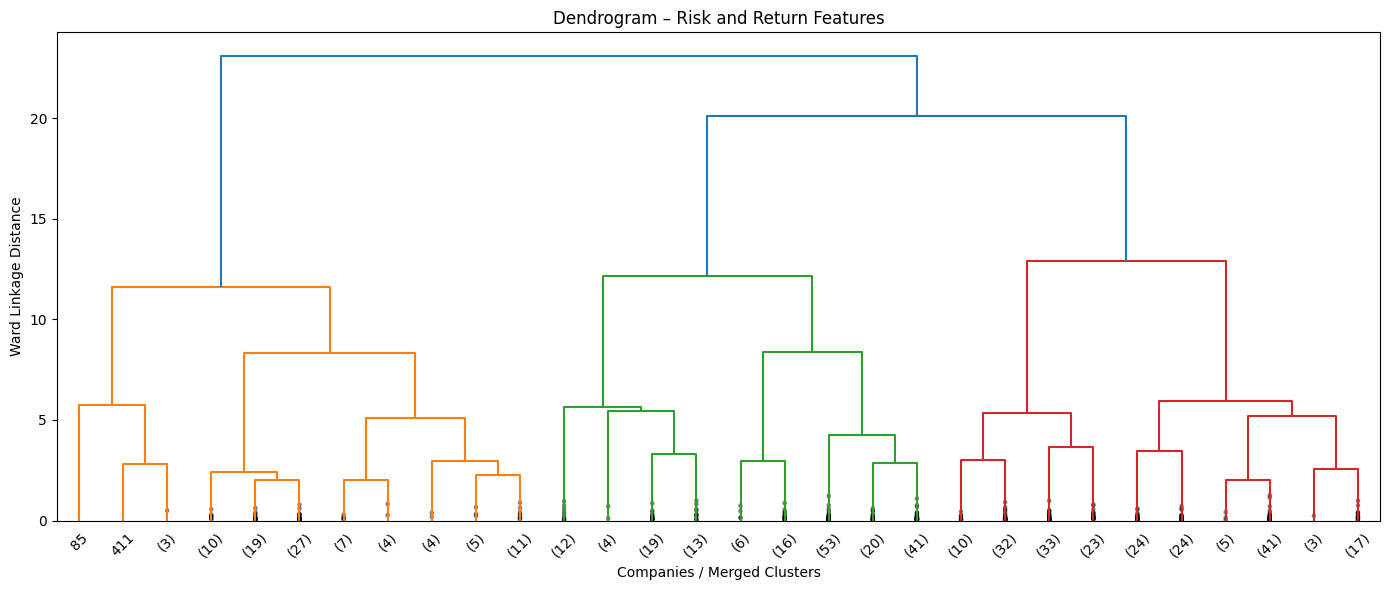

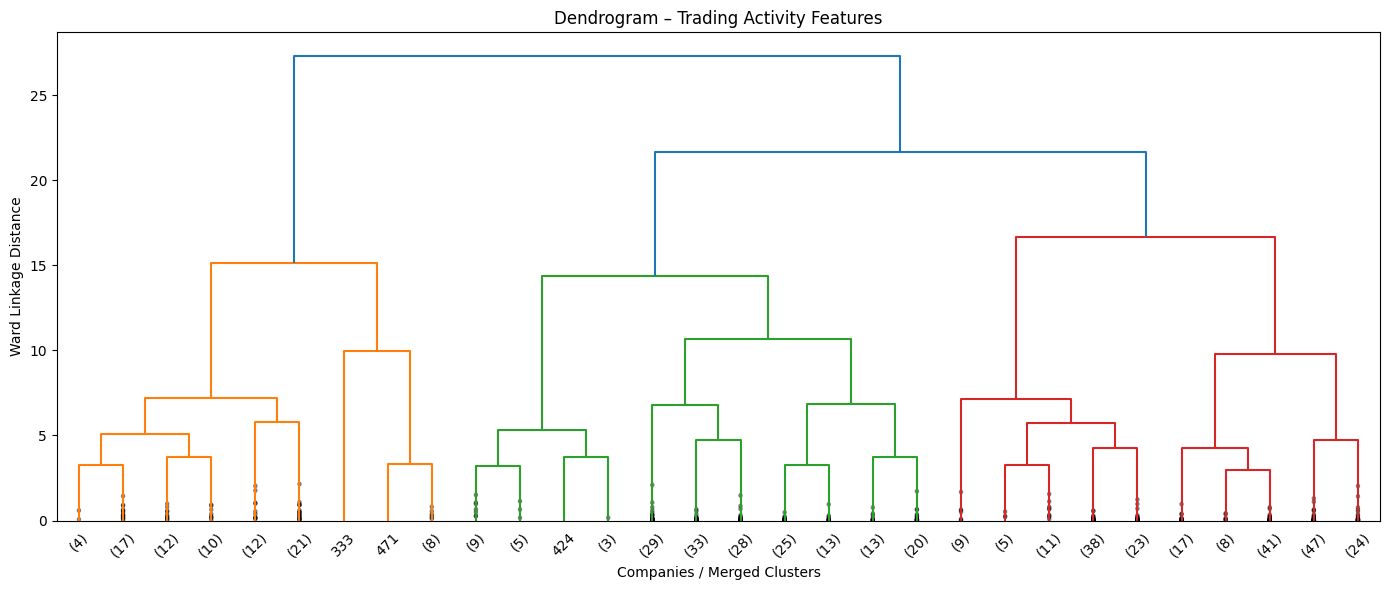

In [ ]:
# Task 2.2 – Step 2: Generate dendrograms

# Calculate hierarchical linkage for both datasets
risk_linkage = linkage(
    X_risk,
    method="ward",
    metric="euclidean"
)

activity_linkage = linkage(
    X_activity,
    method="ward",
    metric="euclidean"
)

# Dendrogram for Risk and Return
plt.figure(figsize=(14, 6))

dendrogram(
    risk_linkage,
    truncate_mode="lastp",
    p=30,
    show_contracted=True
)

plt.title("Dendrogram – Risk and Return Features")
plt.xlabel("Companies / Merged Clusters")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()


# Dendrogram for Trading Activity
plt.figure(figsize=(14, 6))

dendrogram(
    activity_linkage,
    truncate_mode="lastp",
    p=30,
    show_contracted=True
)

plt.title("Dendrogram – Trading Activity Features")
plt.xlabel("Companies / Merged Clusters")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()

In [ ]:
# Task 2.2 – Step 3: Compare cluster counts from 2 to 8

cluster_results = {}
comparison_results = []

datasets = {
    "Risk and Return": X_risk,
    "Trading Activity": X_activity
}

for dataset_name, X in datasets.items():

    cluster_results[dataset_name] = {}

    for k in range(2, 9):

        # Apply Agglomerative Clustering
        model = AgglomerativeClustering(
            n_clusters=k,
            linkage="ward",
            metric="euclidean"
        )

        labels = model.fit_predict(X)

        # Calculate silhouette score
        score = silhouette_score(X, labels)

        # Calculate cluster sizes
        cluster_sizes = pd.Series(labels).value_counts().sort_index()

        # Store labels
        cluster_results[dataset_name][k] = labels

        # Store comparison results
        comparison_results.append({
            "Dataset": dataset_name,
            "Clusters": k,
            "Silhouette_Score": score,
            "Smallest_Cluster": cluster_sizes.min(),
            "Largest_Cluster": cluster_sizes.max(),
            "Cluster_Sizes": cluster_sizes.to_dict()
        })

# Create comparison table
cluster_comparison = pd.DataFrame(comparison_results)

display(
    cluster_comparison[
        [
            "Dataset",
            "Clusters",
            "Silhouette_Score",
            "Smallest_Cluster",
            "Largest_Cluster",
            "Cluster_Sizes"
        ]
    ].round(4)
)

,Dataset,Clusters,Silhouette_Score,Smallest_Cluster,Largest_Cluster,Cluster_Sizes
0,Risk and Return,2,0.3399,92,396,"{0: 396, 1: 92}"
1,Risk and Return,3,0.2929,92,212,"{0: 212, 1: 92, 2: 184}"
2,Risk and Return,4,0.2654,92,184,"{0: 184, 1: 92, 2: 114, 3: 98}"
3,Risk and Return,5,0.2873,48,136,"{0: 92, 1: 136, 2: 114, 3: 98, 4: 48}"
4,Risk and Return,6,0.3041,5,136,"{0: 136, 1: 87, 2: 114, 3: 98, 4: 48, 5: 5}"
5,Risk and Return,7,0.3061,5,114,"{0: 87, 1: 48, 2: 114, 3: 98, 4: 114, 5: 5, 6:..."
6,Risk and Return,8,0.3138,5,114,"{0: 114, 1: 48, 2: 5, 3: 98, 4: 114, 5: 31, 6:..."
7,Trading Activity,2,0.3693,86,402,"{0: 402, 1: 86}"
8,Trading Activity,3,0.2614,86,223,"{0: 223, 1: 86, 2: 179}"
9,Trading Activity,4,0.2514,86,179,"{0: 86, 1: 137, 2: 179, 3: 86}"


In [ ]:
# Task 2.2 – Step 4: Generate cluster profiles

# Fit 2-cluster Agglomerative models
risk_model_2 = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward",
    metric="euclidean"
)

activity_model_2 = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward",
    metric="euclidean"
)

# Assign cluster labels
risk_labels_2 = risk_model_2.fit_predict(X_risk)
activity_labels_2 = activity_model_2.fit_predict(X_activity)

# Create profile datasets using original feature values
risk_profile_data = risk_return_final.copy()
risk_profile_data["Cluster"] = risk_labels_2

activity_profile_data = trading_activity_final.copy()
activity_profile_data["Cluster"] = activity_labels_2

# Risk and Return cluster profiles
risk_profiles = risk_profile_data.groupby("Cluster").agg(
    Company_Count=("Ticker", "count"),
    Mean_Weekly_Return=("Mean_Weekly_Return", "mean"),
    Average_Beta=("Weekly_Beta", "mean")
).round(5)

print("RISK AND RETURN CLUSTER PROFILES")
display(risk_profiles)

# Trading Activity cluster profiles
# Note: We aggregate on M_Monetary_Log since M_Monetary_USD is not in trading_activity_final
activity_profiles = activity_profile_data.groupby("Cluster").agg(
    Company_Count=("Ticker", "count"),
    Average_Recency=("R_Recency", "mean"),
    Average_Frequency=("F_Frequency", "mean"),
    Average_Monetary_Log=("M_Monetary_Log", "mean")
).round(2)

# Add an estimated USD column back by reversing the log transformation for interpretation
activity_profiles["Est_Average_Monetary_USD"] = np.expm1(activity_profiles["Average_Monetary_Log"])

print("TRADING ACTIVITY CLUSTER PROFILES")
display(activity_profiles)

RISK AND RETURN CLUSTER PROFILES


,Company_Count,Mean_Weekly_Return,Average_Beta
Cluster,,,
0,396,0.00205,0.89854
1,92,0.00632,1.29808


TRADING ACTIVITY CLUSTER PROFILES


,Company_Count,Average_Recency,Average_Frequency,Average_Monetary_Log,Est_Average_Monetary_USD
Cluster,,,,,
0,402,12.56,3.20,23.64,1.848083e+10
1,86,57.00,1.98,23.86,2.302854e+10


In [ ]:
# Task 2.2 – Step 5: Compare cluster sizes

print("Risk and Return cluster sizes:")
display(risk_profile_data["Cluster"].value_counts().sort_index())

print("\nTrading Activity cluster sizes:")
display(activity_profile_data["Cluster"].value_counts().sort_index())

Risk and Return cluster sizes:


,count
Cluster,
0,396
1,92



Trading Activity cluster sizes:


,count
Cluster,
0,402
1,86


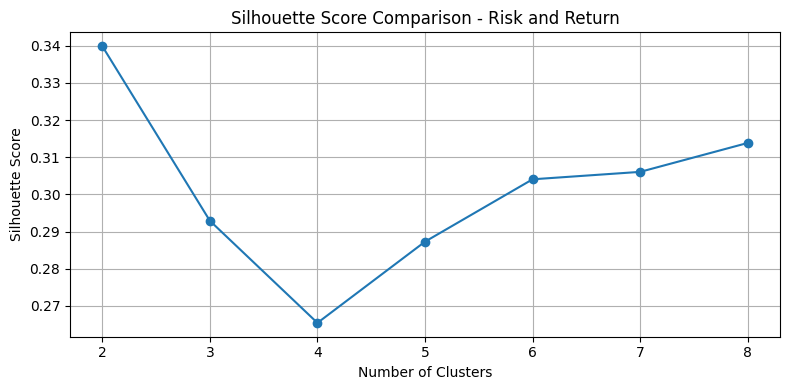

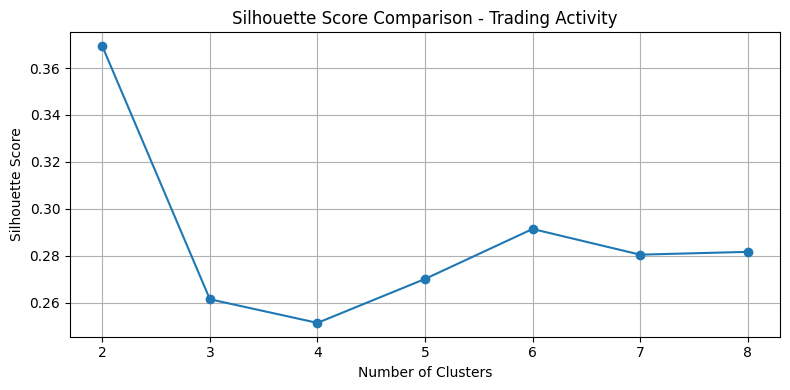

In [ ]:
# Task 2.2 – Step 6: Visualise silhouette scores

for dataset_name in cluster_comparison["Dataset"].unique():

    subset = cluster_comparison[
        cluster_comparison["Dataset"] == dataset_name
    ]

    plt.figure(figsize=(8, 4))

    plt.plot(
        subset["Clusters"],
        subset["Silhouette_Score"],
        marker="o"
    )

    plt.title(f"Silhouette Score Comparison - {dataset_name}")
    plt.xlabel("Number of Clusters")
    plt.ylabel("Silhouette Score")
    plt.xticks(range(2, 9))
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [ ]:
# Task 2.2 - Step 7: Compare the selected cluster solutions

selected_results = cluster_comparison[
    cluster_comparison["Clusters"] == 2
].copy()

selected_results = selected_results[
    [
        "Dataset",
        "Clusters",
        "Silhouette_Score",
        "Smallest_Cluster",
        "Largest_Cluster",
        "Cluster_Sizes"
    ]
]

print("FINAL AGGLOMERATIVE CLUSTERING COMPARISON")
display(selected_results)

FINAL AGGLOMERATIVE CLUSTERING COMPARISON


,Dataset,Clusters,Silhouette_Score,Smallest_Cluster,Largest_Cluster,Cluster_Sizes
0,Risk and Return,2,0.339888,92,396,"{0: 396, 1: 92}"
7,Trading Activity,2,0.369340,86,402,"{0: 402, 1: 86}"


In [ ]:
# Check the highest silhouette score for each dataset

best_solutions = (
    cluster_comparison.loc[
        cluster_comparison.groupby("Dataset")["Silhouette_Score"].idxmax()
    ]
)

print("BEST CLUSTER SOLUTION FOR EACH DATASET")
display(best_solutions)

BEST CLUSTER SOLUTION FOR EACH DATASET


,Dataset,Clusters,Silhouette_Score,Smallest_Cluster,Largest_Cluster,Cluster_Sizes
0,Risk and Return,2,0.339888,92,396,"{0: 396, 1: 92}"
7,Trading Activity,2,0.369340,86,402,"{0: 402, 1: 86}"


In [ ]:
# Task 2.2 - Step 8: Save final cluster assignments

# Risk and Return cluster assignments
risk_cluster_assignments = risk_return_final[["Ticker"]].copy()
risk_cluster_assignments["Agglomerative_Cluster"] = risk_labels_2

# Trading Activity cluster assignments
activity_cluster_assignments = trading_activity_final[["Ticker"]].copy()
activity_cluster_assignments["Agglomerative_Cluster"] = activity_labels_2

# Export the assignments
risk_cluster_assignments.to_csv(
    "Task2_Risk_Return_Agglomerative_Clusters.csv", index=False
)

activity_cluster_assignments.to_csv(
    "Task2_Trading_Activity_Agglomerative_Clusters.csv", index=False
)

print("Risk and Return assignments:")
display(risk_cluster_assignments.head())

print("Trading Activity assignments:")
display(activity_cluster_assignments.head())

print("Total risk and return assignments:", len(risk_cluster_assignments))
print("Total trading activity assignments:", len(activity_cluster_assignments))

Risk and Return assignments:


,Ticker,Agglomerative_Cluster
0,MMM,0
1,AOS,0
2,ABT,0
3,ABBV,0
4,ACN,0


Trading Activity assignments:


,Ticker,Agglomerative_Cluster
0,MMM,0
1,AOS,0
2,ABT,0
3,ABBV,0
4,ACN,0


Total risk and return assignments: 488
Total trading activity assignments: 488


Task 2.3 - K means clustering

In [ ]:
# Task 2.3 - Step 1: Prepare K-means datasets

X_risk_kmeans = risk_scaled.to_numpy()
X_activity_kmeans = activity_scaled.to_numpy()

print("Risk and Return matrix:", X_risk_kmeans.shape)
print("Trading Activity matrix:", X_activity_kmeans.shape)

print("\nMissing values:")
print("Risk and Return:", np.isnan(X_risk_kmeans).sum())
print("Trading Activity:", np.isnan(X_activity_kmeans).sum())

Risk and Return matrix: (488, 2)
Trading Activity matrix: (488, 3)

Missing values:
Risk and Return: 0
Trading Activity: 0


In [ ]:
# Task 2.3 - Step 2: K-means clustering

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Fixed random seed for reproducibility
RANDOM_SEED = 42

# Test cluster numbers from 2 to 8
k_values = range(2, 9)

# Store results and cluster labels
kmeans_results = {}
kmeans_cluster_labels = {}

datasets = {
    "Risk and Return": X_risk_kmeans,
    "Trading Activity": X_activity_kmeans
}

for dataset_name, X in datasets.items():

    kmeans_results[dataset_name] = {}
    kmeans_cluster_labels[dataset_name] = {}

    for k in k_values:

        kmeans_model = KMeans(
            n_clusters=k,
            random_state=RANDOM_SEED,
            n_init=20
        )

        labels = kmeans_model.fit_predict(X)

        silhouette = silhouette_score(X, labels)
        inertia = kmeans_model.inertia_

        cluster_sizes = pd.Series(labels).value_counts().sort_index()

        kmeans_results[dataset_name][k] = {
            "Silhouette_Score": silhouette,
            "Inertia": inertia,
            "Smallest_Cluster": cluster_sizes.min(),
            "Largest_Cluster": cluster_sizes.max(),
            "Cluster_Sizes": cluster_sizes.to_dict()
        }

        kmeans_cluster_labels[dataset_name][k] = labels

        print(
            f"{dataset_name} | k={k} | "
            f"Silhouette={silhouette:.4f} | "
            f"Inertia={inertia:.2f} | "
            f"Sizes={cluster_sizes.to_dict()}"
        )

Risk and Return | k=2 | Silhouette=0.3868 | Inertia=625.01 | Sizes={0: 143, 1: 345}
Risk and Return | k=3 | Silhouette=0.3278 | Inertia=464.08 | Sizes={0: 166, 1: 203, 2: 119}
Risk and Return | k=4 | Silhouette=0.3253 | Inertia=373.94 | Sizes={0: 167, 1: 41, 2: 149, 3: 131}
Risk and Return | k=5 | Silhouette=0.3400 | Inertia=311.55 | Sizes={0: 171, 1: 109, 2: 50, 3: 27, 4: 131}
Risk and Return | k=6 | Silhouette=0.3344 | Inertia=266.91 | Sizes={0: 112, 1: 160, 2: 5, 3: 43, 4: 111, 5: 57}
Risk and Return | k=7 | Silhouette=0.3549 | Inertia=228.71 | Sizes={0: 76, 1: 80, 2: 16, 3: 48, 4: 38, 5: 143, 6: 87}
Risk and Return | k=8 | Silhouette=0.3578 | Inertia=196.14 | Sizes={0: 81, 1: 48, 2: 139, 3: 37, 4: 5, 5: 30, 6: 72, 7: 76}
Trading Activity | k=2 | Silhouette=0.4238 | Inertia=1071.59 | Sizes={0: 420, 1: 68}
Trading Activity | k=3 | Silhouette=0.3251 | Inertia=800.75 | Sizes={0: 274, 1: 63, 2: 151}
Trading Activity | k=4 | Silhouette=0.3414 | Inertia=612.48 | Sizes={0: 122, 1: 61, 2: 2

In [ ]:
# Task 2.3 - Step 3: Compare K-means results

kmeans_comparison_rows = []

for dataset_name, results in kmeans_results.items():

    for k, metrics in results.items():

        kmeans_comparison_rows.append({
            "Dataset": dataset_name,
            "Clusters": k,
            "Silhouette_Score": metrics["Silhouette_Score"],
            "Inertia": metrics["Inertia"],
            "Smallest_Cluster": metrics["Smallest_Cluster"],
            "Largest_Cluster": metrics["Largest_Cluster"],
            "Cluster_Sizes": metrics["Cluster_Sizes"]
        })

kmeans_comparison = pd.DataFrame(kmeans_comparison_rows)

kmeans_comparison["Silhouette_Score"] = (
    kmeans_comparison["Silhouette_Score"].round(4)
)

kmeans_comparison["Inertia"] = (
    kmeans_comparison["Inertia"].round(2)
)

print("K-MEANS CLUSTERING COMPARISON")
display(kmeans_comparison)

K-MEANS CLUSTERING COMPARISON


,Dataset,Clusters,Silhouette_Score,Inertia,Smallest_Cluster,Largest_Cluster,Cluster_Sizes
0,Risk and Return,2,0.3868,625.01,143,345,"{0: 143, 1: 345}"
1,Risk and Return,3,0.3278,464.08,119,203,"{0: 166, 1: 203, 2: 119}"
2,Risk and Return,4,0.3253,373.94,41,167,"{0: 167, 1: 41, 2: 149, 3: 131}"
3,Risk and Return,5,0.3400,311.55,27,171,"{0: 171, 1: 109, 2: 50, 3: 27, 4: 131}"
4,Risk and Return,6,0.3344,266.91,5,160,"{0: 112, 1: 160, 2: 5, 3: 43, 4: 111, 5: 57}"
5,Risk and Return,7,0.3549,228.71,16,143,"{0: 76, 1: 80, 2: 16, 3: 48, 4: 38, 5: 143, 6:..."
6,Risk and Return,8,0.3578,196.14,5,139,"{0: 81, 1: 48, 2: 139, 3: 37, 4: 5, 5: 30, 6: ..."
7,Trading Activity,2,0.4238,1071.59,68,420,"{0: 420, 1: 68}"
8,Trading Activity,3,0.3251,800.75,63,274,"{0: 274, 1: 63, 2: 151}"
9,Trading Activity,4,0.3414,612.48,61,214,"{0: 122, 1: 61, 2: 214, 3: 91}"


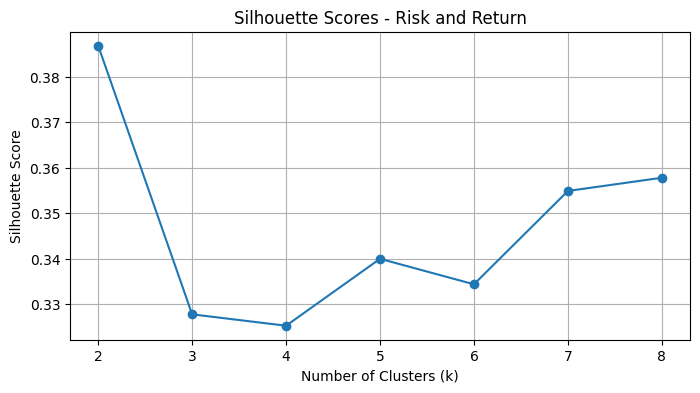

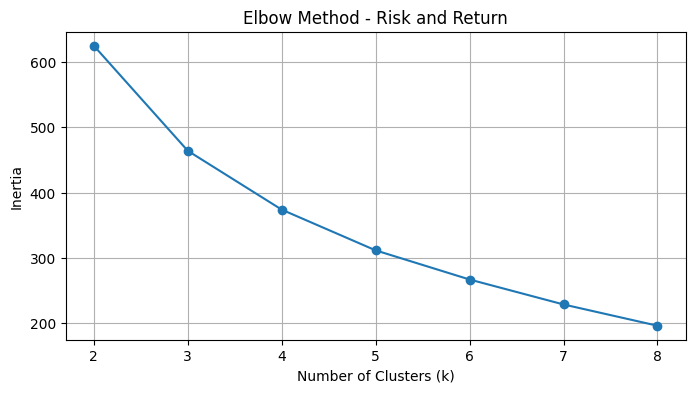

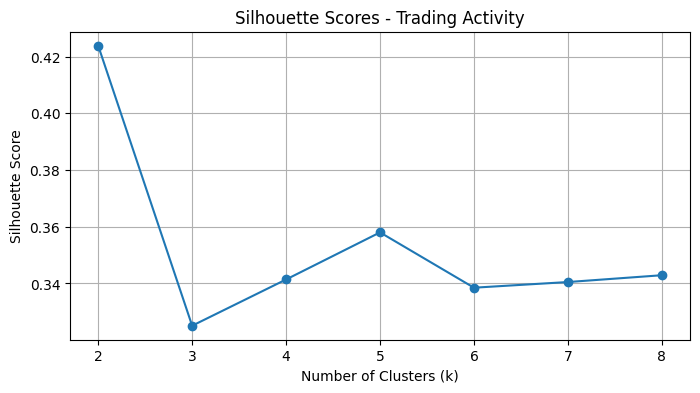

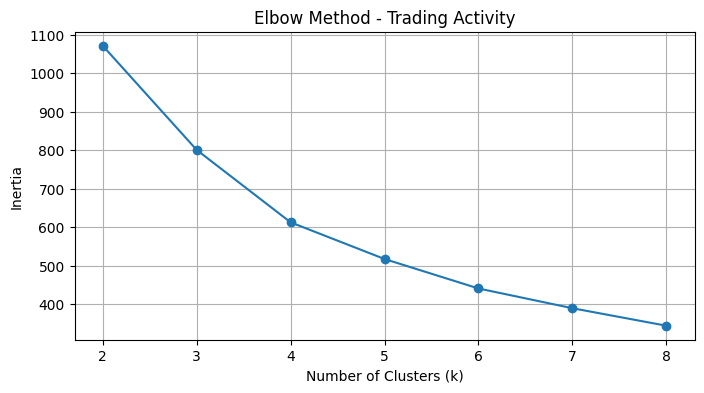

In [ ]:
# Task 2.3 - Step 4: K-means evaluation visualisations

import matplotlib.pyplot as plt

for dataset_name in kmeans_comparison["Dataset"].unique():

    subset = kmeans_comparison[
        kmeans_comparison["Dataset"] == dataset_name
    ]

    # Silhouette score plot
    plt.figure(figsize=(8, 4))
    plt.plot(
        subset["Clusters"],
        subset["Silhouette_Score"],
        marker="o"
    )
    plt.title(f"Silhouette Scores - {dataset_name}")
    plt.xlabel("Number of Clusters (k)")
    plt.ylabel("Silhouette Score")
    plt.xticks(range(2, 9))
    plt.grid(True)
    plt.show()

    # Inertia / Elbow plot
    plt.figure(figsize=(8, 4))
    plt.plot(
        subset["Clusters"],
        subset["Inertia"],
        marker="o"
    )
    plt.title(f"Elbow Method - {dataset_name}")
    plt.xlabel("Number of Clusters (k)")
    plt.ylabel("Inertia")
    plt.xticks(range(2, 9))
    plt.grid(True)
    plt.show()

In [ ]:
# Task 2.3 - Step 5: Identify best K-means solutions

best_kmeans_solutions = kmeans_comparison.loc[
    kmeans_comparison.groupby("Dataset")["Silhouette_Score"].idxmax()
].copy()

print("BEST K-MEANS SOLUTIONS")
display(best_kmeans_solutions)

BEST K-MEANS SOLUTIONS


,Dataset,Clusters,Silhouette_Score,Inertia,Smallest_Cluster,Largest_Cluster,Cluster_Sizes
0,Risk and Return,2,0.3868,625.01,143,345,"{0: 143, 1: 345}"
7,Trading Activity,2,0.4238,1071.59,68,420,"{0: 420, 1: 68}"


In [ ]:
# Task 2.3 - Step 6: Generate K-means cluster profiles

# Get labels for k = 2
risk_kmeans_labels_2 = kmeans_cluster_labels["Risk and Return"][2]
activity_kmeans_labels_2 = kmeans_cluster_labels["Trading Activity"][2]

# Risk and Return profiles
risk_kmeans_profile_data = risk_return_matrix.copy()
risk_kmeans_profile_data["Cluster"] = risk_kmeans_labels_2

risk_kmeans_profiles = risk_kmeans_profile_data.groupby("Cluster").agg(
    Company_Count=("Ticker", "count"),
    Mean_Weekly_Return=("Mean_Weekly_Return", "mean"),
    Average_Beta=("Weekly_Beta", "mean")
).round(5)

print("K-MEANS RISK AND RETURN CLUSTER PROFILES")
display(risk_kmeans_profiles)


# Trading Activity profiles
activity_kmeans_profile_data = trading_activity_matrix.copy()
activity_kmeans_profile_data["Cluster"] = activity_kmeans_labels_2

activity_kmeans_profiles = activity_kmeans_profile_data.groupby("Cluster").agg(
    Company_Count=("Ticker", "count"),
    Average_Recency=("R_Recency", "mean"),
    Average_Frequency=("F_Frequency", "mean"),
    Average_Monetary_USD=("M_Monetary_USD", "mean")
).round(2)

print("K-MEANS TRADING ACTIVITY CLUSTER PROFILES")
display(activity_kmeans_profiles)

K-MEANS RISK AND RETURN CLUSTER PROFILES


,Company_Count,Mean_Weekly_Return,Average_Beta
Cluster,,,
0,143,0.00533,1.35049
1,345,0.00183,0.81776


K-MEANS TRADING ACTIVITY CLUSTER PROFILES


,Company_Count,Average_Recency,Average_Frequency,Average_Monetary_USD
Cluster,,,,
0,420,13.44,3.18,3.260527e+10
1,68,63.34,1.78,8.067057e+10


In [ ]:
# Task 2.3 - Step 7: Save final K-means assignments

# Risk and Return assignments
risk_kmeans_assignments = risk_return_matrix[["Ticker"]].copy()

risk_kmeans_assignments["KMeans_Cluster"] = (
    risk_kmeans_labels_2
)

# Trading Activity assignments
activity_kmeans_assignments = trading_activity_matrix[["Ticker"]].copy()

activity_kmeans_assignments["KMeans_Cluster"] = (
    activity_kmeans_labels_2
)

# Export CSV files
risk_kmeans_assignments.to_csv(
    "Task2_Risk_Return_KMeans_Clusters.csv",
    index=False
)

activity_kmeans_assignments.to_csv(
    "Task2_Trading_Activity_KMeans_Clusters.csv",
    index=False
)

print("Risk and Return K-means assignments:")
display(risk_kmeans_assignments.head())

print("Trading Activity K-means assignments:")
display(activity_kmeans_assignments.head())

print("Total Risk and Return assignments:",
      len(risk_kmeans_assignments))

print("Total Trading Activity assignments:",
      len(activity_kmeans_assignments))

Risk and Return K-means assignments:


,Ticker,KMeans_Cluster
0,MMM,1
1,AOS,1
2,ABT,1
3,ABBV,1
4,ACN,1


Trading Activity K-means assignments:


,Ticker,KMeans_Cluster
0,MMM,0
1,AOS,0
2,ABT,0
3,ABBV,0
4,ACN,0


Total Risk and Return assignments: 488
Total Trading Activity assignments: 488


Task 2.4 - Cluster profiles and algorithm compariosn

In [ ]:
# Task 2.4 - Step 1: Cluster profiles in original units


# 1. Risk and Return - Agglomerative


risk_agg_profile_data = risk_return_matrix.copy()
risk_agg_profile_data["Cluster"] = risk_labels_2

risk_agg_profiles = risk_agg_profile_data.groupby("Cluster").agg(
    Company_Count=("Ticker", "count"),
    Mean_Weekly_Return=("Mean_Weekly_Return", "mean"),
    Average_Beta=("Weekly_Beta", "mean")
).round(5)



# 2. Risk and Return - K-means


risk_kmeans_profile_data = risk_return_matrix.copy()
risk_kmeans_profile_data["Cluster"] = risk_kmeans_labels_2

risk_kmeans_profiles_original = risk_kmeans_profile_data.groupby("Cluster").agg(
    Company_Count=("Ticker", "count"),
    Mean_Weekly_Return=("Mean_Weekly_Return", "mean"),
    Average_Beta=("Weekly_Beta", "mean")
).round(5)



# 3. Trading Activity - Agglomerative


activity_agg_profile_data = trading_activity_matrix.copy()
activity_agg_profile_data["Cluster"] = activity_labels_2

activity_agg_profiles = activity_agg_profile_data.groupby("Cluster").agg(
    Company_Count=("Ticker", "count"),
    Average_Recency=("R_Recency", "mean"),
    Average_Frequency=("F_Frequency", "mean"),
    Average_Monetary_USD=("M_Monetary_USD", "mean")
).round(2)



# 4. Trading Activity - K-means


activity_kmeans_profile_data = trading_activity_matrix.copy()
activity_kmeans_profile_data["Cluster"] = activity_kmeans_labels_2

activity_kmeans_profiles_original = activity_kmeans_profile_data.groupby("Cluster").agg(
    Company_Count=("Ticker", "count"),
    Average_Recency=("R_Recency", "mean"),
    Average_Frequency=("F_Frequency", "mean"),
    Average_Monetary_USD=("M_Monetary_USD", "mean")
).round(2)


# Display all profiles

print("RISK AND RETURN - AGGLOMERATIVE")
display(risk_agg_profiles)

print("RISK AND RETURN - K-MEANS")
display(risk_kmeans_profiles_original)

print("TRADING ACTIVITY - AGGLOMERATIVE")
display(activity_agg_profiles)

print("TRADING ACTIVITY - K-MEANS")
display(activity_kmeans_profiles_original)

RISK AND RETURN - AGGLOMERATIVE


,Company_Count,Mean_Weekly_Return,Average_Beta
Cluster,,,
0,396,0.00205,0.89854
1,92,0.00632,1.29808


RISK AND RETURN - K-MEANS


,Company_Count,Mean_Weekly_Return,Average_Beta
Cluster,,,
0,143,0.00533,1.35049
1,345,0.00183,0.81776


TRADING ACTIVITY - AGGLOMERATIVE


,Company_Count,Average_Recency,Average_Frequency,Average_Monetary_USD
Cluster,,,,
0,402,12.56,3.20,3.738926e+10
1,86,57.00,1.98,4.824805e+10


TRADING ACTIVITY - K-MEANS


,Company_Count,Average_Recency,Average_Frequency,Average_Monetary_USD
Cluster,,,,
0,420,13.44,3.18,3.260527e+10
1,68,63.34,1.78,8.067057e+10


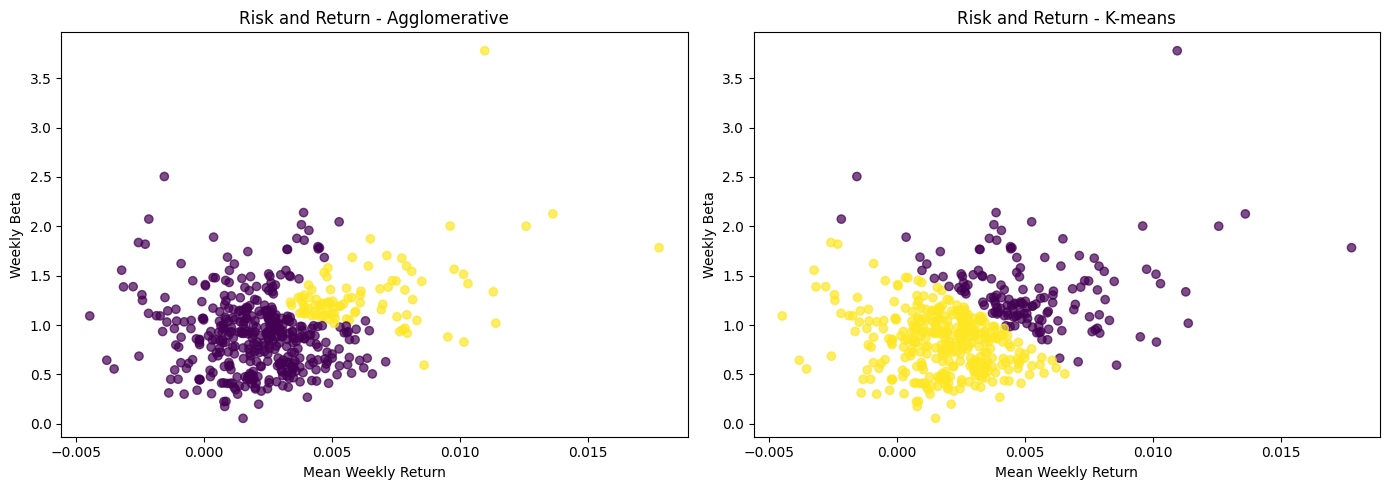

In [ ]:
# Task 2.4 - Step 2A: Risk and Return 2D visualisation

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Agglomerative clustering
axes[0].scatter(
    risk_return_matrix["Mean_Weekly_Return"],
    risk_return_matrix["Weekly_Beta"],
    c=risk_labels_2,
    cmap="viridis",
    alpha=0.7
)

axes[0].set_title("Risk and Return - Agglomerative")
axes[0].set_xlabel("Mean Weekly Return")
axes[0].set_ylabel("Weekly Beta")


# K-means clustering
axes[1].scatter(
    risk_return_matrix["Mean_Weekly_Return"],
    risk_return_matrix["Weekly_Beta"],
    c=risk_kmeans_labels_2,
    cmap="viridis",
    alpha=0.7
)

axes[1].set_title("Risk and Return - K-means")
axes[1].set_xlabel("Mean Weekly Return")
axes[1].set_ylabel("Weekly Beta")

plt.tight_layout()
plt.show()

Explained variance by each component:
PC1: 45.79 %
PC2: 33.65 %
Total variance explained: 79.44 %


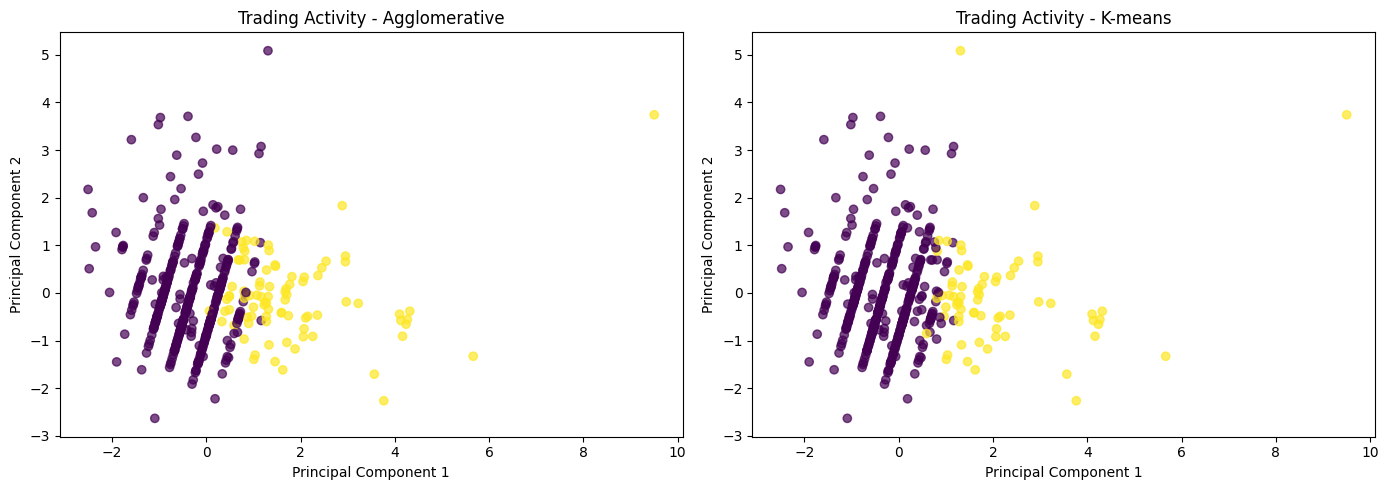

In [ ]:
# Task 2.4 - Step 2B: Trading Activity PCA visualisation

from sklearn.decomposition import PCA

# Reduce the three standardised features to two dimensions
pca = PCA(n_components=2)

activity_pca = pca.fit_transform(X_activity_kmeans)

print("Explained variance by each component:")
print("PC1:", round(pca.explained_variance_ratio_[0] * 100, 2), "%")
print("PC2:", round(pca.explained_variance_ratio_[1] * 100, 2), "%")

print(
    "Total variance explained:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)


# Create two visualisations using the SAME PCA coordinates
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Agglomerative clustering
axes[0].scatter(
    activity_pca[:, 0],
    activity_pca[:, 1],
    c=activity_labels_2,
    cmap="viridis",
    alpha=0.7
)

axes[0].set_title("Trading Activity - Agglomerative")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")


# K-means clustering
axes[1].scatter(
    activity_pca[:, 0],
    activity_pca[:, 1],
    c=activity_kmeans_labels_2,
    cmap="viridis",
    alpha=0.7
)

axes[1].set_title("Trading Activity - K-means")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

In [ ]:
# Task 2.4 - Step 3: Compare clustering algorithms

from sklearn.metrics import adjusted_rand_score

# Risk and Return comparison
risk_ari = adjusted_rand_score(
    risk_labels_2,
    risk_kmeans_labels_2
)

risk_cross_table = pd.crosstab(
    pd.Series(risk_labels_2, name="Agglomerative"),
    pd.Series(risk_kmeans_labels_2, name="KMeans")
)


# Trading Activity comparison
activity_ari = adjusted_rand_score(
    activity_labels_2,
    activity_kmeans_labels_2
)

activity_cross_table = pd.crosstab(
    pd.Series(activity_labels_2, name="Agglomerative"),
    pd.Series(activity_kmeans_labels_2, name="KMeans")
)


print("RISK AND RETURN - ADJUSTED RAND INDEX")
print(round(risk_ari, 4))

print("\nRISK AND RETURN - CLUSTER COMPARISON")
display(risk_cross_table)


print("\nTRADING ACTIVITY - ADJUSTED RAND INDEX")
print(round(activity_ari, 4))

print("\nTRADING ACTIVITY - CLUSTER COMPARISON")
display(activity_cross_table)

RISK AND RETURN - ADJUSTED RAND INDEX
0.5985

RISK AND RETURN - CLUSTER COMPARISON


KMeans,0,1
Agglomerative,,
0,51,345
1,92,0



TRADING ACTIVITY - ADJUSTED RAND INDEX
0.7796

TRADING ACTIVITY - CLUSTER COMPARISON


KMeans,0,1
Agglomerative,,
0,400,2
1,20,66


In [ ]:
# Task 2.4 - Step 4: Combine all clustering assignments

# Start with the common ticker list
algorithm_comparison = pd.DataFrame({
    "Ticker": risk_return_matrix["Ticker"].values,
    "Risk_Agglomerative": risk_labels_2,
    "Risk_KMeans": risk_kmeans_labels_2,
    "Activity_Agglomerative": activity_labels_2,
    "Activity_KMeans": activity_kmeans_labels_2
})

# Check the number of companies and missing values
print("Total companies:", len(algorithm_comparison))
print("Missing values:", algorithm_comparison.isna().sum().sum())
print("Unique companies:", algorithm_comparison["Ticker"].nunique())

display(algorithm_comparison.head(10))

# Export the combined comparison
algorithm_comparison.to_csv(
    "Task2_4_Algorithm_Comparison_All_Companies.csv",
    index=False
)

Total companies: 488
Missing values: 0
Unique companies: 488


,Ticker,Risk_Agglomerative,Risk_KMeans,Activity_Agglomerative,Activity_KMeans
0,MMM,0,1,0,0
1,AOS,0,1,0,0
2,ABT,0,1,0,0
3,ABBV,0,1,0,0
4,ACN,0,1,0,0
5,ADBE,0,0,0,0
6,AMD,0,0,0,0
7,AES,0,1,1,1
8,AFL,0,1,0,0
9,A,0,1,0,0


Task 2.5 - RFM sensitivity and correlated inputs

In [ ]:
# Task 2.5.1 - Step 1: Calculate feature correlations

rfm_features = trading_activity_final[
    ["R_Recency", "F_Frequency", "M_Monetary_Log"]
].copy()

# Calculate Pearson correlation matrix
rfm_correlation = rfm_features.corr(method="pearson")

print("RFM FEATURE CORRELATION MATRIX")
display(rfm_correlation.round(4))

RFM FEATURE CORRELATION MATRIX


,R_Recency,F_Frequency,M_Monetary_Log
R_Recency,1.0000,-0.3461,0.1528
F_Frequency,-0.3461,1.0000,0.0128
M_Monetary_Log,0.1528,0.0128,1.0000


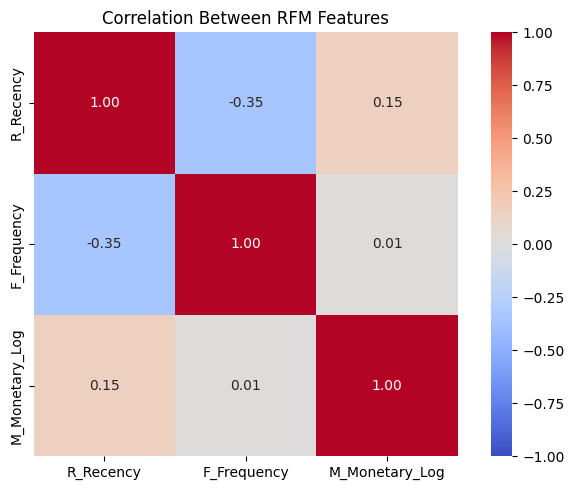

In [ ]:
# Task 2.5.1 - Step 2: Correlation heatmap

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

sns.heatmap(
    rfm_correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Correlation Between RFM Features")
plt.tight_layout()
plt.show()

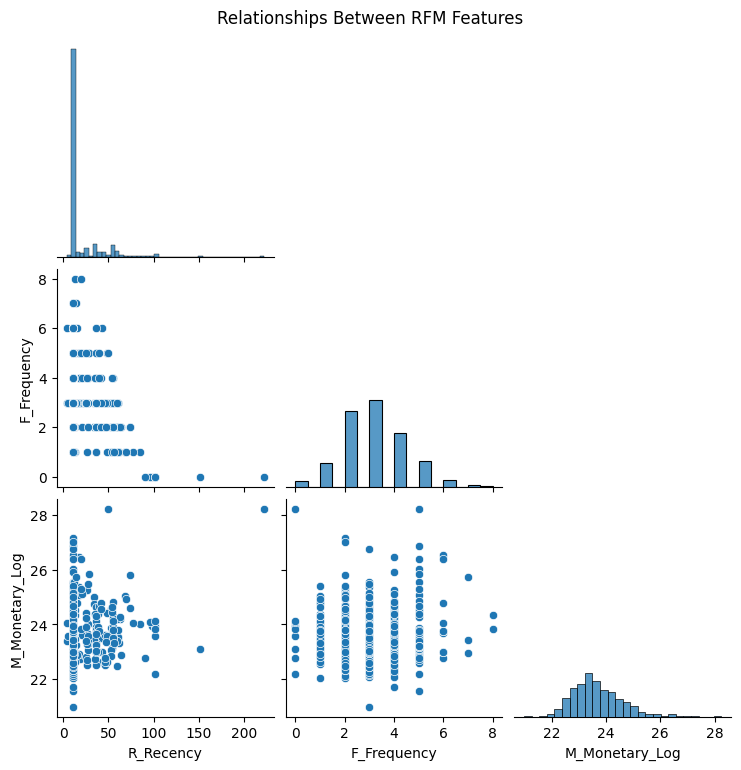

In [ ]:
# Task 2.5.1 - Step 3: Pairwise relationships

sns.pairplot(
    rfm_features,
    diag_kind="hist",
    corner=True
)

plt.suptitle(
    "Relationships Between RFM Features",
    y=1.02
)

plt.show()

In [ ]:
# Task 2.5.2 - Step 4: Prepare R and F only

from sklearn.preprocessing import StandardScaler

rf_matrix = trading_activity_matrix[
    ["Ticker", "R_Recency", "F_Frequency"]
].copy()

print("R and F matrix shape:", rf_matrix.shape)
print("Missing values:", rf_matrix.isna().sum().sum())
print("Unique companies:", rf_matrix["Ticker"].nunique())

display(rf_matrix.head())

R and F matrix shape: (488, 3)
Missing values: 0
Unique companies: 488


,Ticker,R_Recency,F_Frequency
0,MMM,11,4
1,AOS,11,2
2,ABT,11,1
3,ABBV,11,3
4,ACN,11,2


In [ ]:
# Task 2.5.2 - Step 5: Standardise R and F

rf_scaler = StandardScaler()

rf_scaled = pd.DataFrame(
    rf_scaler.fit_transform(
        rf_matrix[["R_Recency", "F_Frequency"]]
    ),
    columns=["R_Recency", "F_Frequency"],
    index=rf_matrix.index
)

print("Standardised R and F matrix:")
display(rf_scaled.head())

print("\nFeature means:")
display(rf_scaled.mean().round(6))

print("\nFeature standard deviations:")
display(rf_scaled.std(ddof=0).round(6))

Standardised R and F matrix:


,R_Recency,F_Frequency
0,-0.441208,0.762582
1,-0.441208,-0.744058
2,-0.441208,-1.497377
3,-0.441208,0.009262
4,-0.441208,-0.744058



Feature means:


,0
R_Recency,-0.0
F_Frequency,-0.0



Feature standard deviations:


,0
R_Recency,1.0
F_Frequency,1.0


In [ ]:
# Task 2.5.2 - Step 6: Ward clustering with R and F only

rf_model = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward",
    metric="euclidean"
)

rf_labels = rf_model.fit_predict(rf_scaled)

print("R and F cluster sizes:")
display(pd.Series(rf_labels).value_counts().sort_index())

print("\nTotal assigned companies:", len(rf_labels))

R and F cluster sizes:


,count
0,398
1,90



Total assigned companies: 488


In [ ]:
# Task 2.5.2 – Compare RFM and R+F Ward clustering

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score
import pandas as pd

# Fit Ward clustering using the freshly standardised R and F features
X_rf = rf_scaled.to_numpy() if hasattr(rf_scaled, "to_numpy") else rf_scaled

rf_model = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward",
    metric="euclidean"
)

rf_labels_2 = rf_model.fit_predict(X_rf)

# Check that both solutions contain the same companies in the same order
assert len(rf_labels_2) == len(activity_labels_2) == len(trading_activity_matrix)
assert trading_activity_matrix["Ticker"].is_unique

# Compare cluster membership using Adjusted Rand Index
ari_score = adjusted_rand_score(activity_labels_2, rf_labels_2)

print("Adjusted Rand Index:", round(ari_score, 4))

# Create a comparison table
comparison_25 = trading_activity_matrix[
    ["Ticker", "R_Recency", "F_Frequency", "M_Monetary_USD"]
].copy()

comparison_25["RFM_Cluster"] = activity_labels_2
comparison_25["RF_Cluster"] = rf_labels_2

print("\nCluster membership comparison:")
print(pd.crosstab(
    comparison_25["RFM_Cluster"],
    comparison_25["RF_Cluster"]
))

# Profile the original RFM clusters using original values
rfm_profile_25 = comparison_25.groupby("RFM_Cluster").agg(
    Companies=("Ticker", "count"),
    Average_Recency=("R_Recency", "mean"),
    Average_Frequency=("F_Frequency", "mean"),
    Average_Traded_Value=("M_Monetary_USD", "mean"),
    Median_Traded_Value=("M_Monetary_USD", "median")
).round(2)

print("\nOriginal RFM cluster profiles:")
display(rfm_profile_25)

# Profile the reduced R+F clusters using original values
rf_profile_25 = comparison_25.groupby("RF_Cluster").agg(
    Companies=("Ticker", "count"),
    Average_Recency=("R_Recency", "mean"),
    Average_Frequency=("F_Frequency", "mean"),
    Average_Traded_Value=("M_Monetary_USD", "mean"),
    Median_Traded_Value=("M_Monetary_USD", "median")
).round(2)

print("\nReduced R+F cluster profiles:")
display(rf_profile_25)

# Confirm all companies were assigned
print("\nTotal assigned companies:", comparison_25["RF_Cluster"].notna().sum())
print("Unique companies:", comparison_25["Ticker"].nunique())
print("Missing cluster assignments:", comparison_25["RF_Cluster"].isna().sum())

Adjusted Rand Index: 0.9225

Cluster membership comparison:
RF_Cluster     0   1
RFM_Cluster         
0            396   6
1              2  84

Original RFM cluster profiles:


,Companies,Average_Recency,Average_Frequency,Average_Traded_Value,Median_Traded_Value
RFM_Cluster,,,,,
0,402,12.56,3.20,3.738926e+10,1.539575e+10
1,86,57.00,1.98,4.824805e+10,2.145008e+10



Reduced R+F cluster profiles:


,Companies,Average_Recency,Average_Frequency,Average_Traded_Value,Median_Traded_Value
RF_Cluster,,,,,
0,398,12.30,3.21,3.773977e+10,1.546039e+10
1,90,56.17,2.01,4.621541e+10,2.048974e+10



Total assigned companies: 488
Unique companies: 488
Missing cluster assignments: 0


In [ ]:
from google.colab import files

files.download("Task2_4_Algorithm_Comparison_All_Companies.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
plt.savefig("my_chart.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>